In [1]:
RUTA_DRIVE = '/content/drive/MyDrive/TP Grupal DMA/'

try:
    from google.colab import drive
    drive.mount('/content/drive')
    RUTA = RUTA_DRIVE
    EN_COLAB = True
except ImportError:
    RUTA = ''
    EN_COLAB = False

print('Corriendo en Colab' if EN_COLAB else 'Corriendo en Jupyter local', '| ruta de datos:', RUTA + 'data.csv')

Mounted at /content/drive
Corriendo en Colab | ruta de datos: /content/drive/MyDrive/TP Grupal DMA/data.csv


# TP Grupal – Desarrollo de Modelos Analíticos
**UTN FRBA · 2do cuatrimestre 2026 · Grupo 1**

Theo Dyzenchauz · Claudio H. Luciano Sonntag · Ariel Habib · Camila Agustina Sanchez · Manuel Verger

## Objetivo de negocio
El banco quiere saber **qué clientes tienen más probabilidad de comprar el producto**, para que Marketing concentre la campaña en ellos.
El modelo (LightGBM) le asigna a cada cliente un **score** y lo ubica en un **decil**: decil 1 = el 10% con más chances, decil 10 = el 10% con menos.

## Cómo está armado este notebook
- **Parte 1 – TP individual, tal cual se entregó** (universo, target, nulos, outliers, ABT y categóricas). Lo único que cambia es la ruta del `data.csv` para que funcione en Colab.
- **Parte 2 – Modelo**: train/test, reducción de variables, hiperparámetros, performance, feature importance, conclusiones y simulación de campaña.


---
# Parte 1 – TP individual

# TP Desarrollo de Modelos Analíticos
UTN FRBA 2do cuatrimestre 2026  


# Objetivo
Construir la ABT (Analytic Base Table) a partir de la base historica mensual de clientes del banco (`data.csv`). Una fila por cliente, con sus variables y el target.

1. Carga de datos y armado del universo y el target.
2. Analisis de nulos: que variables tienen nulos y como se completan (foco en Tipo de Tarjeta y Región).
3. Analisis de outliers en 4 variables de montos en pesos.
4. Armado de la ABT: identity, transform y aggregate features (30 variables numericas)
5. Tratamiento de variables categoricas: bines, % de target y One Hot Encoding.
6. ABT final.

## 0. Librerías

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')

## 1. Carga de datos



In [3]:
data = pd.read_csv(RUTA + 'data.csv', sep='|', low_memory=False)
data.shape

(238616, 77)

In [4]:
data.head()

,client_id,Target,Month,First_product_dt,Last_product_dt,CreditCard_Premium,CreditCard_Active,CreditCard_CoBranding,Loan_Active,Mortgage_Active,...,CreditCard_Payment_External,CreditCard_Payment_Cash,CreditCard_Payment_Web,CreditCard_Payment_ATM,CreditCard_Payment_TAS,Investment_Numbers,Mobile,Email,Region,CreditCard_Product
0,5856970,1.0,2018-10-01,2013-10-23,2019-01-10,No,Yes,No,No,No,...,0.0,0.0,0.0,0.0,0.0,1.0,Yes,Yes,NaN,NaN
1,6371753,0.0,2018-09-01,2015-07-29,2018-06-02,No,No,No,No,No,...,0.0,0.0,0.0,0.0,0.0,0.0,Yes,No,NaN,NaN
2,5928737,0.0,2019-01-01,2016-08-31,2018-12-27,No,No,No,No,No,...,0.0,0.0,0.0,0.0,0.0,0.0,Yes,Yes,NaN,NaN
3,475064,0.0,2018-12-01,2014-07-13,2017-11-30,No,Yes,No,No,No,...,0.0,0.0,0.0,0.0,0.0,0.0,Yes,Yes,NaN,NaN
4,3615172,0.0,2018-09-01,2017-12-27,2017-12-28,No,No,No,No,No,...,0.0,0.0,0.0,0.0,0.0,0.0,Yes,No,NaN,NaN


In [5]:
data.tail(2)[['client_id', 'Target', 'Month']]

,client_id,Target,Month
238614,5921880,0.0,2019-03-01
238615,(238615 rows affected),NaN,NaN


In [6]:
# ultima fila no tiene mes y dejo client_id como entero
data = data[data['Month'].notnull()].copy()
data['client_id'] = data['client_id'].astype(int)
data.shape

(238615, 77)

In [7]:
data.columns


Index(['client_id', 'Target', 'Month', 'First_product_dt', 'Last_product_dt',
       'CreditCard_Premium', 'CreditCard_Active', 'CreditCard_CoBranding',
       'Loan_Active', 'Mortgage_Active', 'SavingAccount_Active_ARG_Salary',
       'SavingAccount_Active_ARG', 'SavingAccount_Active_DOLLAR',
       'DebitCard_Active', 'Investment_Active', 'Package_Active',
       'Insurance_Life', 'Insurance_Home', 'Insurance_Accidents',
       'Insurance_Mobile', 'Insurance_ATM', 'Insurance_Unemployment', 'Sex',
       'Client_Age_grp', 'SavingAccount_Balance_FirstDate',
       'SavingAccount_Balance_LastDate', 'SavingAccount_Balance_Average',
       'SavingAccount_Days_with_use', 'SavingAccount_Days_with_Credits',
       'SavingAccount_Days_with_Debits',
       'SavingAccount_Salary_Payment_Transactions',
       'SavingAccount_Transfer_In_Transactions',
       'SavingAccount_ATM_Extraction_Transactions',
       'SavingAccount_Service_Payment_Transactions',
       'SavingAccount_CreditCard_Payment_T

In [8]:
data.dtypes


,0
client_id,int64
Target,float64
Month,object
First_product_dt,object
Last_product_dt,object
...,...
Investment_Numbers,float64
Mobile,object
Email,object
Region,object


In [9]:
data['Month'].value_counts()


,count
Month,
2019-03-01,26547
2019-04-01,26547
2019-02-01,26512
2019-01-01,26503
2018-08-01,26502
2018-10-01,26501
2018-09-01,26501
2018-12-01,26501
2018-11-01,26501


Va dsede agosto de 2018 a abril de 2019 con aprox. 26.500 clientes por mes. La estructura es una fila por cliente por mes: hay que llevarla a una fila por cliente que seria la ABT.

Ventanas de tiempo:
- Historia (train): agosto 2018 a enero 2019 6 meses de aca salen las variables
- Gap: febrero 2019.
- Target: marzo y abril 2019, si el cliente tiene `Target = 1` en alguno de esos meses TGT = 1.

### 1.1 Universo

In [10]:
train = data[data['Month'].isin(['2018-08-01', '2018-09-01', '2018-10-01', '2018-11-01', '2018-12-01', '2019-01-01'])].copy()


# Clientes presentes los 9 meses
con_9_meses = data['client_id'].value_counts().reset_index()
con_9_meses.columns = ['client_id', 'meses']
con_9_meses['meses'].value_counts()

,count
meses,
9,26483
2,38
8,9
7,9
3,9
4,6
1,6


In [11]:
train['Month'].value_counts()


,count
Month,
2019-01-01,26503
2018-08-01,26502
2018-09-01,26501
2018-10-01,26501
2018-12-01,26501
2018-11-01,26501


In [12]:
# Clientes sin paquete en enero 2019
sin_paquete   = data[(data['Month'] == '2019-01-01') & (data['Package_Active'] == 'No')]
sin_paquete.shape

(26026, 77)

In [13]:
# Clientes sin tarjeta co-branding en enero 2019
sin_cobranding = data[(data['Month'] == '2019-01-01') & (data['CreditCard_CoBranding'] == 'No')]
sin_cobranding.shape


(23660, 77)

In [14]:
# Armo el universo

universo = con_9_meses[con_9_meses['meses'] == 9]\
                .merge(sin_paquete, how='inner', on='client_id')\
                .merge(sin_cobranding, how='inner', on='client_id')[['client_id']].drop_duplicates()
universo.shape

(23191, 1)

In [15]:
train['client_id'].value_counts()


,count
client_id,
5967858,6
5856970,6
6371753,6
5928737,6
475064,6
...,...
6264756,2
1419642,1
5124642,1


### 1.2 Target

In [16]:
pred = data[data['Month'].isin(['2019-03-01', '2019-04-01'])].copy()

pred_tgt = pred[pred['Target'] == 1][['client_id']].drop_duplicates()
pred_tgt['TGT'] = 1

universo = universo.merge(pred_tgt, how='left', on='client_id')
universo['TGT'] = universo['TGT'].fillna(0).astype(int)

print(universo['TGT'].value_counts())
print('\nTasa de target: {:.1%}'.format(universo['TGT'].mean()))

TGT
0    16368
1     6823
Name: count, dtype: int64

Tasa de target: 29.4%


### 1.3 Historia del universo

In [17]:
data_train = universo[['client_id']].merge(train, how='inner', on='client_id')
print('data_train:', data_train.shape, '->', data_train['client_id'].nunique(), 'clientes x 6 meses')

data_train: (139146, 77) -> 23191 clientes x 6 meses


# 2. Análisis de nulos

In [18]:
data_train.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 139146 entries, 0 to 139145
Data columns (total 77 columns):
 #   Column                                         Non-Null Count   Dtype  
---  ------                                         --------------   -----  
 0   client_id                                      139146 non-null  int64  
 1   Target                                         139146 non-null  float64
 2   Month                                          139146 non-null  object 
 3   First_product_dt                               139146 non-null  object 
 4   Last_product_dt                                139146 non-null  object 
 5   CreditCard_Premium                             139146 non-null  object 
 6   CreditCard_Active                              139146 non-null  object 
 7   CreditCard_CoBranding                          139146 non-null  object 
 8   Loan_Active                                    139146 non-null  object 
 9   Mortgage_Active                      

In [19]:
data_train.columns[data_train.isnull().any()].tolist()


['SavingAccount_Balance_Average', 'Region', 'CreditCard_Product']

Region y Tipo de Tarjeta solo tienen valor en marzo y abril 2019, así que hay que buscarlas en esos meses.

### 2.1 SavingAccount_Balance_Average


In [20]:
data_train[data_train['SavingAccount_Balance_Average'].isnull()][['client_id', 'Month', 'SavingAccount_Balance_Average']]

,client_id,Month,SavingAccount_Balance_Average
5684,4525957,2019-01-01,NaN
23231,6412619,2019-01-01,NaN
67814,4837071,2018-12-01,NaN
90229,4473325,2018-12-01,NaN


In [21]:
data_train[data_train['client_id'] == 4525957][['client_id','SavingAccount_Balance_Average', 'Month']]


,client_id,SavingAccount_Balance_Average,Month
5682,4525957,35.76,2018-09-01
5683,4525957,303.46,2018-11-01
5684,4525957,NaN,2019-01-01
5685,4525957,307.69,2018-10-01
5686,4525957,308.18,2018-12-01
5687,4525957,149.72,2018-08-01


In [22]:
data_train[data_train['client_id'] == 6412619][['client_id','SavingAccount_Balance_Average', 'Month']]


,client_id,SavingAccount_Balance_Average,Month
23226,6412619,177.06,2018-09-01
23227,6412619,53.17,2018-12-01
23228,6412619,63.38,2018-10-01
23229,6412619,184.49,2018-08-01
23230,6412619,176.71,2018-11-01
23231,6412619,NaN,2019-01-01


In [23]:
data_train[data_train['client_id'] == 4837071][['client_id','SavingAccount_Balance_Average', 'Month']]


,client_id,SavingAccount_Balance_Average,Month
67812,4837071,311.08,2018-10-01
67813,4837071,369.97,2018-11-01
67814,4837071,NaN,2018-12-01
67815,4837071,961.28,2018-09-01
67816,4837071,1471.20,2019-01-01
67817,4837071,313.07,2018-08-01


In [24]:
data_train[data_train['client_id'] == 4473325][['client_id','SavingAccount_Balance_Average', 'Month']]


,client_id,SavingAccount_Balance_Average,Month
90228,4473325,1974.19,2018-10-01
90229,4473325,NaN,2018-12-01
90230,4473325,2129.53,2018-11-01
90231,4473325,1272.27,2019-01-01
90232,4473325,2102.36,2018-09-01
90233,4473325,4804.80,2018-08-01


In [25]:
# Completo el saldo promedio con el promedio entre el saldo del primer y del último día del mes
data_train['SavingAccount_Balance_Average'] = np.where(
    data_train['SavingAccount_Balance_Average'].isnull(),
    (data_train['SavingAccount_Balance_FirstDate'] + data_train['SavingAccount_Balance_LastDate']) / 2,
    data_train['SavingAccount_Balance_Average'])



In [26]:
data_train[data_train['client_id'] == 4525957][['client_id','SavingAccount_Balance_Average', 'Month']]


,client_id,SavingAccount_Balance_Average,Month
5682,4525957,35.76,2018-09-01
5683,4525957,303.46,2018-11-01
5684,4525957,878.77,2019-01-01
5685,4525957,307.69,2018-10-01
5686,4525957,308.18,2018-12-01
5687,4525957,149.72,2018-08-01


In [27]:
data_train[data_train['client_id'] == 6412619][['client_id','SavingAccount_Balance_Average', 'Month']]


,client_id,SavingAccount_Balance_Average,Month
23226,6412619,177.06,2018-09-01
23227,6412619,53.17,2018-12-01
23228,6412619,63.38,2018-10-01
23229,6412619,184.49,2018-08-01
23230,6412619,176.71,2018-11-01
23231,6412619,76.39,2019-01-01


In [28]:
data_train[data_train['client_id'] == 4837071][['client_id','SavingAccount_Balance_Average', 'Month']]


,client_id,SavingAccount_Balance_Average,Month
67812,4837071,311.08,2018-10-01
67813,4837071,369.97,2018-11-01
67814,4837071,5325.79,2018-12-01
67815,4837071,961.28,2018-09-01
67816,4837071,1471.20,2019-01-01
67817,4837071,313.07,2018-08-01


In [29]:
data_train[data_train['client_id'] == 4473325][['client_id','SavingAccount_Balance_Average', 'Month']]


,client_id,SavingAccount_Balance_Average,Month
90228,4473325,1974.19,2018-10-01
90229,4473325,205.51,2018-12-01
90230,4473325,2129.53,2018-11-01
90231,4473325,1272.27,2019-01-01
90232,4473325,2102.36,2018-09-01
90233,4473325,4804.80,2018-08-01


### 2.2 Tipo de Tarjeta (`CreditCard_Product`)

Logica:
1. Tomo si el cliente tiene tarjeta activa en enero 2019 (`CreditCard_Active`).
2. Busco el producto de tarjeta en el mes futuro más cercano, marzo 2019.
3. Si no tiene tarjeta activa va a categoría `No tiene`.
4. Si tiene tarjeta pero no encuentro el producto completo con la categoría más popular

In [30]:
data_tarj = data_train[data_train['Month'] == '2019-01-01'][['client_id', 'CreditCard_Active']]
data_tarj_futuro = data[data['Month'] == '2019-03-01'][['client_id', 'CreditCard_Product']]

data_tarj = data_tarj.merge(data_tarj_futuro, how='left', on='client_id')
pd.crosstab(data_tarj['CreditCard_Product'].fillna('NULO'), data_tarj['CreditCard_Active'])

CreditCard_Active,No,Yes
CreditCard_Product,,
J55660102XX012,7,402
J55660104XX012,148,8279
J55660123XX012,7,1
J55660124XX012,37,29
J55660202XX012,101,5777
J55660702XX012,13,248
J55661002XX012,3,58
NULO,7852,229


- La mayoria de los que no tienen tarjeta activa tienen el producto nulo
- Hay algunos sin tarjeta activa pero con producto en marzo sacaron la tarjeta después de enero, como en enero no la tenían, los pongo como `No tiene`
- Hay clientes con tarjeta activa pero sin producto en marzo, esos se completan con la categoría mas popular.

In [31]:
data_tarj['CreditCard_Product'] = np.where(data_tarj['CreditCard_Active'] == 'Yes',
                                          data_tarj['CreditCard_Product'], 'No tiene')
data_tarj['CreditCard_Product'] = data_tarj['CreditCard_Product'].fillna('No encontre la tarjeta')
data_tarj['CreditCard_Product'].value_counts()

,count
CreditCard_Product,
J55660104XX012,8279
No tiene,8168
J55660202XX012,5777
J55660102XX012,402
J55660702XX012,248
No encontre la tarjeta,229
J55661002XX012,58
J55660124XX012,29
J55660123XX012,1


In [32]:
# Pongo la categoria mas popular

data_tarj['CreditCard_Product'] = np.where(data_tarj['CreditCard_Product'] == 'No encontre la tarjeta', 'J55660104XX012',
                                          data_tarj['CreditCard_Product'])

In [33]:
data_tarj['CreditCard_Product'].value_counts()

,count
CreditCard_Product,
J55660104XX012,8508
No tiene,8168
J55660202XX012,5777
J55660102XX012,402
J55660702XX012,248
J55661002XX012,58
J55660124XX012,29
J55660123XX012,1


### 2.3 Región

La región es un dato del cliente que no deberia cambiar de un mes a otro. Lo verifico y después la busco en marzo 2019, si no está, en abril 2019 y si sigue sin aparecer, completo con la categoría mas popular.

In [34]:
region_futuro = data[data['Month'].isin(['2019-03-01', '2019-04-01']) & data['Region'].notnull()]
print('Regiones distintas por cliente:')
print(region_futuro.groupby('client_id')['Region'].nunique().value_counts())

Regiones distintas por cliente:
Region
1    26544
Name: count, dtype: int64


 - todos los clientes tienen una sola region

In [35]:
reg_mar = data[data['Month'] == '2019-03-01'][['client_id', 'Region']]
reg_abr = data[data['Month'] == '2019-04-01'][['client_id', 'Region']].rename(columns={'Region': 'Region_abr'})

data_region = universo[['client_id']].merge(reg_mar, how='left', on='client_id').merge(reg_abr, how='left', on='client_id')
print('Sin región en marzo:', data_region['Region'].isnull().sum())

data_region['Region'] = data_region['Region'].fillna(data_region['Region_abr'])
print('Sin región en marzo ni abril:', data_region['Region'].isnull().sum())

Sin región en marzo: 6
Sin región en marzo ni abril: 6


In [36]:
data_region['Region'].value_counts(dropna=False)

,count
Region,
BUENOS AIRES,6984
REGION CENTRO,4579
REGION NORTE GRANDE ARGENTINO,3674
REGION PATAGONICA,2432
CABA Centro/Norte,2048
AMBA Resto,1828
REGION CUYO,1640
NaN,6


In [37]:
# Pongo la region más popular
data_region['Region'] = data_region['Region'].fillna('BUENOS AIRES')
data_region = data_region[['client_id', 'Region']]

print('Nulos restantes:', data_region['Region'].isnull().sum())
data_region['Region'].value_counts()

Nulos restantes: 0


,count
Region,
BUENOS AIRES,6990
REGION CENTRO,4579
REGION NORTE GRANDE ARGENTINO,3674
REGION PATAGONICA,2432
CABA Centro/Norte,2048
AMBA Resto,1828
REGION CUYO,1640


## 3. Analisis de outliers

Tomo 4 variables de montos en pesos:
1. SavingAccount_Balance_Average
2. SavingAccount_Salary_Payment_Amount
3. CreditCard_Total_Spending
4. CreditCard_Total_Limit  

Metodos para tratarlos: recortar en el percentil 99, en el percentil 95, en 3 desvios estandar, o crear bines.


In [38]:
vars_outliers = ['SavingAccount_Balance_Average', 'SavingAccount_Salary_Payment_Amount',
                 'CreditCard_Total_Spending', 'CreditCard_Total_Limit']

data_train[vars_outliers].describe(percentiles=[.25, .5, .75, .95, .99]).T

,count,mean,std,min,25%,50%,75%,95%,99%,max
SavingAccount_Balance_Average,139146.0,4094.832872,22939.386474,-566.59,0.0,10.325,1473.1375,17043.6600,70055.6800,1771200.61
SavingAccount_Salary_Payment_Amount,139146.0,2921.143780,16997.080023,0.00,0.0,0.000,0.0000,22890.7775,58568.9505,2551357.60
CreditCard_Total_Spending,139146.0,4226.449880,7290.005070,-30164.77,0.0,1482.710,5656.1475,17131.6725,33148.2355,176554.25
CreditCard_Total_Limit,139146.0,52001.821827,61612.706040,0.00,0.0,40000.000,64000.0000,160000.0000,280000.0000,625000.00


In [39]:
def resumen_outliers(df, var):
    mayor0 = df[df[var] > 0][var]
    return pd.Series({
        '% ceros':   (df[var] == 0).mean() * 100,
        'mediana >0': mayor0.median(),
        'p95 >0':    mayor0.quantile(0.95),
        'p99 >0':    mayor0.quantile(0.99),
        'media + 3 sigma >0': mayor0.mean() + 3 * mayor0.std(),
        'máximo':    mayor0.max(),
        'registros > p99': (df[var] > mayor0.quantile(0.99)).sum()
    })

tabla_outliers = pd.DataFrame({v: resumen_outliers(data_train, v) for v in vars_outliers}).T
tabla_outliers

,% ceros,mediana >0,p95 >0,p99 >0,media + 3 sigma >0,máximo,registros > p99
SavingAccount_Balance_Average,43.725296,1100.445,30766.570,107113.5908,98014.568619,1771200.61,781.0
SavingAccount_Salary_Payment_Amount,91.550602,26504.350,83197.604,156867.7624,179230.481264,2551357.60,118.0
CreditCard_Total_Spending,39.112874,4519.610,21493.435,39356.3905,31756.274743,176554.25,847.0
CreditCard_Total_Limit,30.114412,56000.000,200000.000,320000.0000,258477.185090,625000.00,679.0


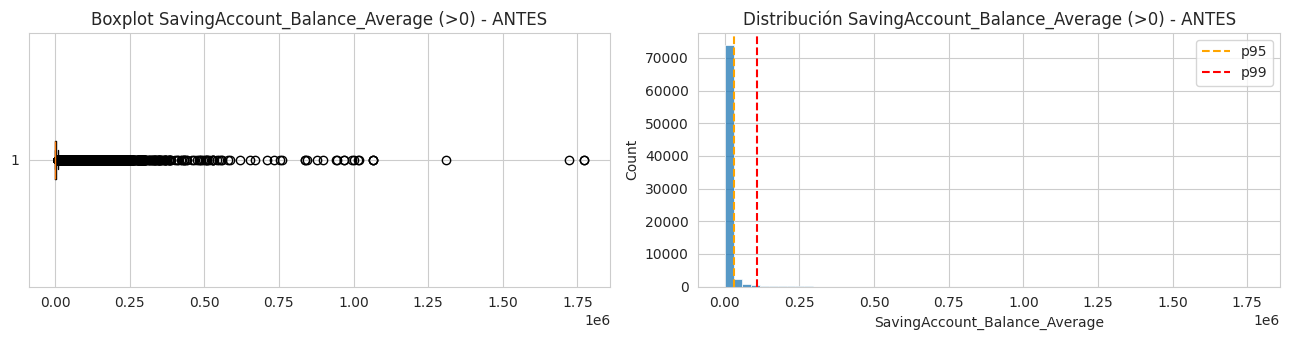

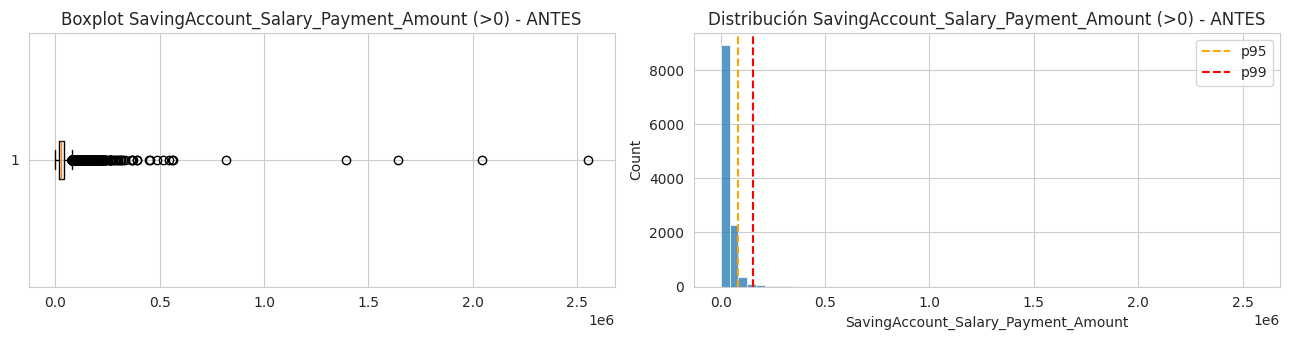

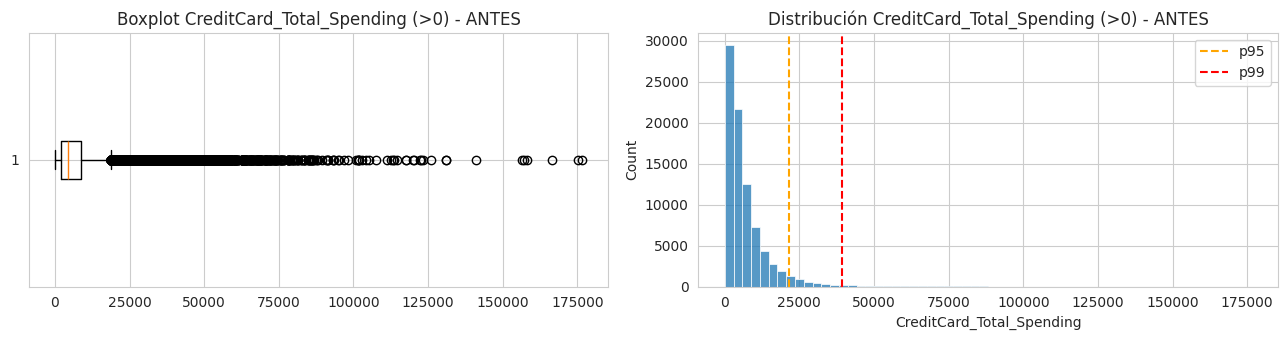

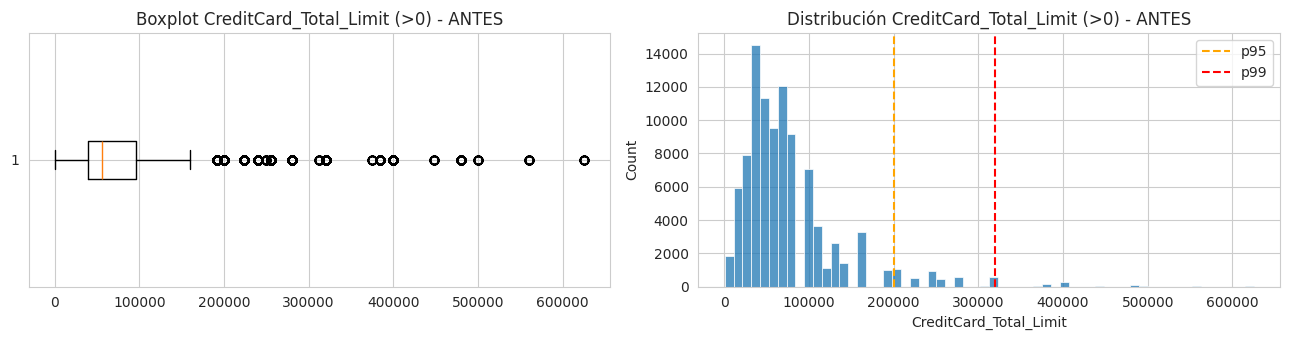

In [40]:
def graficar(df, var, titulo=''):
    mayor0 = df[df[var] > 0][var]
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
    ax[0].boxplot(mayor0, vert=False)
    ax[0].set_title(f'Boxplot {var} (>0) {titulo}')
    sns.histplot(mayor0, bins=60, ax=ax[1])
    for q, c in [(0.95, 'orange'), (0.99, 'red')]:
        ax[1].axvline(mayor0.quantile(q), color=c, linestyle='--', label=f'p{int(q*100)}')
    ax[1].legend()
    ax[1].set_title(f'Distribución {var} (>0) {titulo}')
    plt.tight_layout()
    plt.show()

for v in vars_outliers:
    graficar(data_train, v, '- ANTES')

- La mayoría de los clientes se concentran en valores bajos y unos pocos tienen montos muchisimos más altos.
- Recortar (capping) en el percentil 99 de los valores > 0: todo valor por encima del p99 se reemplaza por el p99. Es el metodo menos restrictivo, solo modifica el 1% más alto, no elimina clientes y conserva el orden. El percentil 95 recortaria demasiada información y 3 sigma depende de la media y el desvio, que justamente estan inflados por los outliers.



In [41]:
limites = {}
for v in vars_outliers:
    limites[v] = data_train[data_train[v] > 0][v].quantile(0.99)
    data_train[v] = np.where(data_train[v] > limites[v], limites[v], data_train[v])

pd.Series(limites, name='tope aplicado (p99)').to_frame()

,tope aplicado (p99)
SavingAccount_Balance_Average,107113.5908
SavingAccount_Salary_Payment_Amount,156867.7624
CreditCard_Total_Spending,39356.3905
CreditCard_Total_Limit,320000.0000


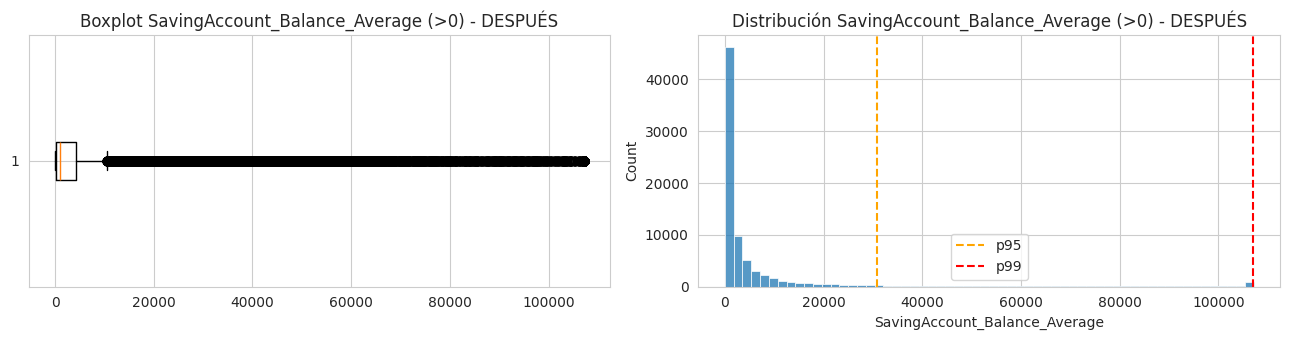

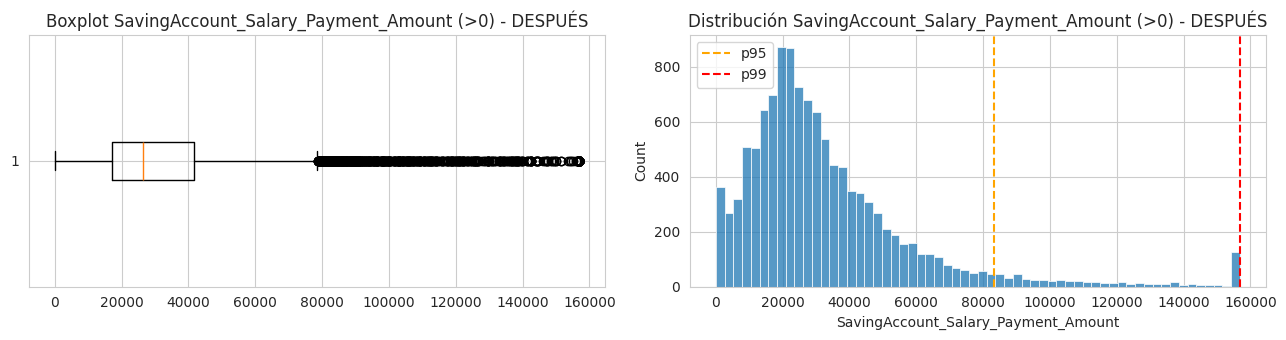

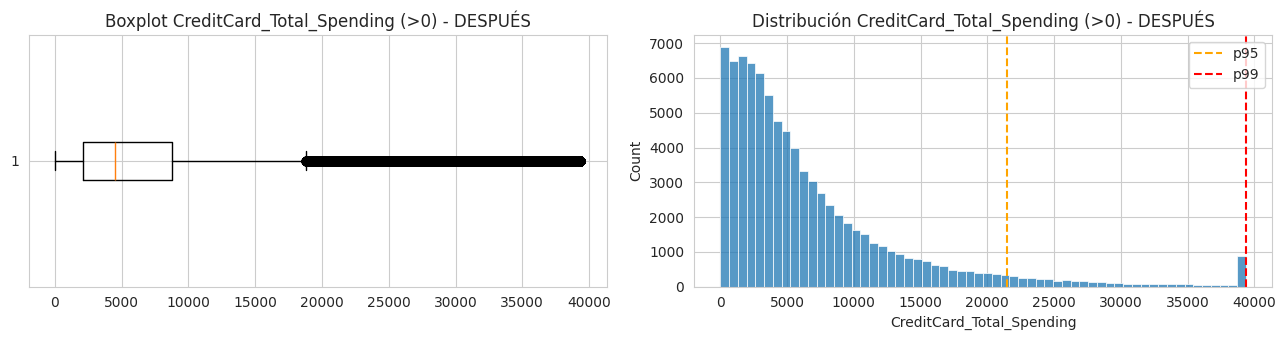

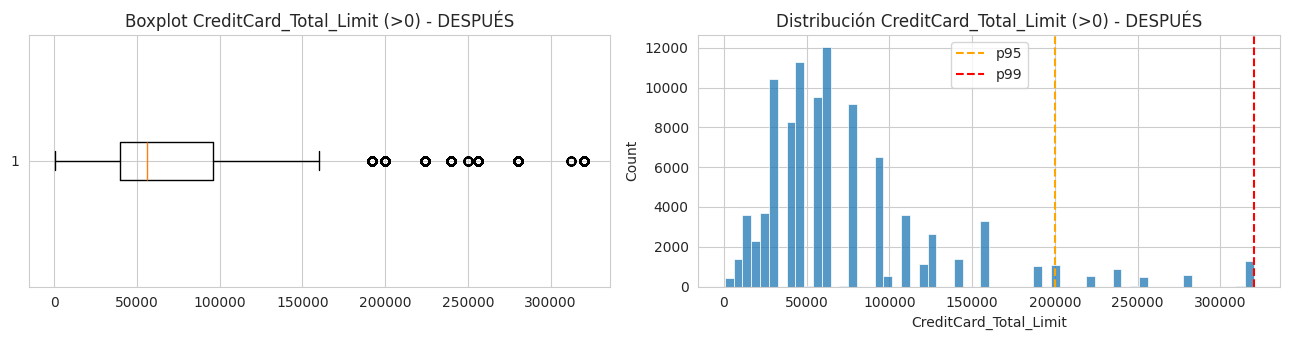

In [42]:
for v in vars_outliers:
    graficar(data_train, v, '- DESPUÉS')

In [43]:
# Comparación antes / después
despues = pd.DataFrame({v: resumen_outliers(data_train, v) for v in vars_outliers}).T
pd.concat([tabla_outliers[['máximo', 'media + 3 sigma >0']].add_suffix(' ANTES'),
           despues[['máximo', 'media + 3 sigma >0']].add_suffix(' DESPUÉS')], axis=1)

,máximo ANTES,media + 3 sigma >0 ANTES,máximo DESPUÉS,media + 3 sigma >0 DESPUÉS
SavingAccount_Balance_Average,1771200.61,98014.568619,107113.5908,52796.989352
SavingAccount_Salary_Payment_Amount,2551357.60,179230.481264,156867.7624,112241.972021
CreditCard_Total_Spending,176554.25,31756.274743,39356.3905,28241.795915
CreditCard_Total_Limit,625000.00,258477.185090,320000.0000,244483.312877


- Despues del recorte, el maximo de cada variable queda en el p99 y el rango "media + 3 sigma" se achica mucho, lo que muestra que el desvío estaba inflado por unos pocos valores extremos.

## 4. Armado de la ABT

Tipos de variables:
- Identity features: se usan tal cual vienen de la base foto del último mes, enero 2019.
- Transform features: se crean con alguna lógica a partir de otras (ej. antiguedad, cantidad de productos activos).
- Aggregate features: se aplican funciones a una variable en una ventana de tiempo (ej. máximo del saldo en los últimos 3 meses).

### 4.1 Identity features

In [44]:
foto = data_train[data_train['Month'] == '2019-01-01'].copy()

identity_features = foto[['client_id', 'SavingAccount_Balance_Average', 'CreditCard_Total_Limit',
                          'Investment_Numbers', 'Sex', 'Client_Age_grp']]
identity_features.head()

,client_id,SavingAccount_Balance_Average,CreditCard_Total_Limit,Investment_Numbers,Sex,Client_Age_grp
2,4221845,0.00,48000.0,0.0,F,Entre 40 y 49 años
9,7219504,1137.43,0.0,0.0,F,Entre 30 y 39 años
16,5882370,0.00,48000.0,0.0,F,Entre 65 y 69 años
18,1158013,0.00,32000.0,0.0,M,Entre 40 y 49 años
27,3914580,545.98,0.0,0.0,F,Entre 30 y 39 años


### 4.2 Transform features

In [45]:
transform_features = foto[['client_id', 'Month', 'First_product_dt', 'Last_product_dt',
       'CreditCard_Premium', 'CreditCard_Active', 'Loan_Active', 'Mortgage_Active',
       'SavingAccount_Active_ARG_Salary', 'SavingAccount_Active_ARG', 'SavingAccount_Active_DOLLAR',
       'DebitCard_Active', 'Investment_Active',
       'Insurance_Life', 'Insurance_Home', 'Insurance_Accidents',
       'Insurance_Mobile', 'Insurance_ATM', 'Insurance_Unemployment', 'Mobile', 'Email']].copy()
transform_features.head(2).T


,2,9
client_id,4221845,7219504
Month,2019-01-01,2019-01-01
First_product_dt,2010-07-25,2018-01-05
Last_product_dt,2010-07-25,2018-01-05
CreditCard_Premium,No,No
CreditCard_Active,Yes,Yes
Loan_Active,No,Yes
Mortgage_Active,No,No
SavingAccount_Active_ARG_Salary,No,No
SavingAccount_Active_ARG,No,Yes


In [46]:
transform_features['CreditCard_Premium'].value_counts()

,count
CreditCard_Premium,
No,20516
Yes,2675


In [47]:
# Paso los Yes / No a 1 / 0
diccionario = {'Yes': 1, 'No': 0}

cols = ['CreditCard_Premium', 'CreditCard_Active', 'Loan_Active', 'Mortgage_Active',
        'SavingAccount_Active_ARG_Salary', 'SavingAccount_Active_ARG', 'SavingAccount_Active_DOLLAR',
        'DebitCard_Active', 'Investment_Active',
        'Insurance_Life', 'Insurance_Home', 'Insurance_Accidents',
        'Insurance_Mobile', 'Insurance_ATM', 'Insurance_Unemployment', 'Mobile', 'Email']

transform_features[cols] = transform_features[cols].replace(diccionario).astype(int)

transform_features['CreditCard_Premium'].value_counts()


,count
CreditCard_Premium,
0,20516
1,2675


In [48]:
# Paso las fechas de texto a formato fecha
transform_features['Month'] = pd.to_datetime(transform_features['Month'])
transform_features['First_product_dt'] = pd.to_datetime(transform_features['First_product_dt'])
transform_features['Last_product_dt'] = pd.to_datetime(transform_features['Last_product_dt'])

transform_features[['Month', 'First_product_dt', 'Last_product_dt']].head()

,Month,First_product_dt,Last_product_dt
2,2019-01-01,2010-07-25,2010-07-25
9,2019-01-01,2018-01-05,2018-01-05
16,2019-01-01,2013-11-17,2013-11-17
18,2019-01-01,2008-06-24,2013-10-28
27,2019-01-01,2008-01-27,2019-01-04


In [49]:
# Calculo antiguedades en meses (resto fechas, me da días, divido por 30)

# Tiempo entre el primer y el ultimo producto
transform_features['Last_First_product_Months'] = (transform_features['Last_product_dt'] - transform_features['First_product_dt']).dt.days / 30

# Antiguedad del cliente: desde su primer producto hasta enero 2019
transform_features['Month_First_product_Months'] = (transform_features['Month'] - transform_features['First_product_dt']).dt.days / 30

# Hace cuanto saco su ultimo producto
transform_features['Month_Last_product_Months'] = (transform_features['Month'] - transform_features['Last_product_dt']).dt.days / 30

transform_features[['First_product_dt', 'Last_product_dt', 'Month',
                    'Last_First_product_Months', 'Month_First_product_Months', 'Month_Last_product_Months']].head()

,First_product_dt,Last_product_dt,Month,Last_First_product_Months,Month_First_product_Months,Month_Last_product_Months
2,2010-07-25,2010-07-25,2019-01-01,0.000000,102.733333,102.733333
9,2018-01-05,2018-01-05,2019-01-01,0.000000,12.033333,12.033333
16,2013-11-17,2013-11-17,2019-01-01,0.000000,62.366667,62.366667
18,2008-06-24,2013-10-28,2019-01-01,65.066667,128.100000,63.033333
27,2008-01-27,2019-01-04,2019-01-01,133.166667,133.066667,-0.100000


In [50]:
# Cuento cuantos seguros tiene (sumo las 6 columnas de seguros)
transform_features['Active_Insurance'] = transform_features['Insurance_Life'] \
                                       + transform_features['Insurance_Home'] \
                                       + transform_features['Insurance_Accidents'] \
                                       + transform_features['Insurance_Mobile'] \
                                       + transform_features['Insurance_ATM'] \
                                       + transform_features['Insurance_Unemployment']

# Cuento cuantos productos tiene (sumo los 7 productos + 1 si tiene algun seguro)
transform_features['Active_Products'] = transform_features['Loan_Active'] \
                                      + transform_features['CreditCard_Active'] \
                                      + transform_features['Mortgage_Active'] \
                                      + transform_features['SavingAccount_Active_ARG'] \
                                      + transform_features['SavingAccount_Active_DOLLAR'] \
                                      + transform_features['DebitCard_Active'] \
                                      + transform_features['Investment_Active'] \
                                      + np.where(transform_features['Active_Insurance'] > 0, 1, 0)

# Borro las fechas reemplazadas por las antiguedades
transform_features = transform_features.drop(['Month', 'First_product_dt', 'Last_product_dt'], axis=1)

print(transform_features['Active_Products'].value_counts().sort_index())
transform_features.set_index('client_id').head().T

Active_Products
0      17
1    6628
2    2680
3    6040
4    5726
5    1992
6     106
7       2
Name: count, dtype: int64


client_id,4221845,7219504,5882370,1158013,3914580
CreditCard_Premium,0.000000,0.000000,1.000000,0.000000,0.000000
CreditCard_Active,1.000000,1.000000,1.000000,1.000000,0.000000
Loan_Active,0.000000,1.000000,0.000000,0.000000,0.000000
Mortgage_Active,0.000000,0.000000,0.000000,0.000000,0.000000
SavingAccount_Active_ARG_Salary,0.000000,0.000000,0.000000,0.000000,0.000000
SavingAccount_Active_ARG,0.000000,1.000000,0.000000,0.000000,1.000000
SavingAccount_Active_DOLLAR,0.000000,0.000000,0.000000,0.000000,1.000000
DebitCard_Active,0.000000,0.000000,0.000000,0.000000,1.000000
Investment_Active,0.000000,0.000000,0.000000,0.000000,0.000000
Insurance_Life,0.000000,0.000000,0.000000,0.000000,0.000000


In [51]:
# Ratio creditos vs debitos de la caja de ahorro en el ultimo mes
ratio = foto[['client_id', 'SavingAccount_Credits_Amounts', 'SavingAccount_Debits_Amounts']].copy()
ratio['SavingAccount_Credits_vs_Debits_Amounts'] = np.where(ratio['SavingAccount_Debits_Amounts'] == 0,
                                                            ratio['SavingAccount_Credits_Amounts'],
                                                            ratio['SavingAccount_Credits_Amounts'] / ratio['SavingAccount_Debits_Amounts'])
transform_features = transform_features.merge(ratio[['client_id', 'SavingAccount_Credits_vs_Debits_Amounts']], how='left', on='client_id')
transform_features.shape

(23191, 24)

### 4.3 Aggregate features

30 variables numericas de tres dimensiones, caja de ahorro, operaciones por canal y tarjeta de crédito.


- Ultimos 6 meses (U6M) | suma, máximo, mínimo, promedio, mediana, cantidad de meses distintos de cero, valores distintos, desvío |
- Últimos 3 meses (U3M) | suma, máximo, mínimo, promedio, mediana, cantidad de meses distintos de cero, valores distintos, desvío |
- Variación | enero vs noviembre (mes 0 vs mes 2), enero vs agosto (mes 0 vs mes 5) y noviembre vs agosto (mes 2 vs mes 5), absoluta y relativa |



In [52]:
vars_agregar = [
    # Caja de ahorro (15)
    'SavingAccount_Balance_Average', 'SavingAccount_Balance_LastDate', 'SavingAccount_Total_Amount',
    'SavingAccount_Days_with_use', 'SavingAccount_Days_with_Credits', 'SavingAccount_Days_with_Debits',
    'SavingAccount_Salary_Payment_Amount', 'SavingAccount_Transfer_In_Amount', 'SavingAccount_Transfer_Out_Amount',
    'SavingAccount_ATM_Extraction_Amount', 'SavingAccount_Service_Payment_Amount', 'SavingAccount_DebitCard_Spend_Amount',
    'SavingAccount_CreditCard_Payment_Amount',
    'SavingAccount_Credits_Transactions', 'SavingAccount_Debits_Transactions',
    # Operaciones por canal (4)
    'Operations_Bank', 'Operations_HomeBanking', 'Operations_Mobile', 'Operations_ATM',
    # Tarjeta de crédito (11)
    'CreditCard_Total_Limit', 'CreditCard_Total_Spending', 'CreditCard_Spending_1_Installment',
    'CreditCard_Spending_Installments', 'CreditCard_Spending_CrossBoarder', 'CreditCard_Spending_Aut_Debits',
    'CreditCard_Balance_ARG', 'CreditCard_Balance_DOLLAR', 'CreditCard_Revolving',
    'CreditCard_Payment_Aut_Debit', 'CreditCard_Payment_External']

In [53]:
def no_cero(x):
    return (x != 0).sum()

# --- Últimos 6 meses
agg_u6m = data_train.groupby('client_id')[vars_agregar].agg(['sum', 'max', 'min', 'mean', 'median', no_cero, 'nunique', 'std'])
agg_u6m.columns = [f'{v}_{f}_u6m' for v, f in agg_u6m.columns]

# --- Últimos 3 meses
u3m = data_train[data_train['Month'].isin(['2018-11-01', '2018-12-01', '2019-01-01'])]
agg_u3m = u3m.groupby('client_id')[vars_agregar].agg(['sum', 'max', 'min', 'mean', 'median', no_cero, 'nunique', 'std'])
agg_u3m.columns = [f'{v}_{f}_u3m' for v, f in agg_u3m.columns]

print('U6M:', agg_u6m.shape, ' U3M:', agg_u3m.shape)
agg_u6m.head(2).T.head(10)

U6M: (23191, 240)  U3M: (23191, 240)


client_id,1030,1094
SavingAccount_Balance_Average_sum_u6m,14439.63000,0.0
SavingAccount_Balance_Average_max_u6m,4799.60000,0.0
SavingAccount_Balance_Average_min_u6m,1206.45000,0.0
SavingAccount_Balance_Average_mean_u6m,2406.60500,0.0
SavingAccount_Balance_Average_median_u6m,2029.75500,0.0
SavingAccount_Balance_Average_no_cero_u6m,6.00000,0.0
SavingAccount_Balance_Average_nunique_u6m,6.00000,1.0
SavingAccount_Balance_Average_std_u6m,1358.26562,0.0
SavingAccount_Balance_LastDate_sum_u6m,11724.86000,0.0
SavingAccount_Balance_LastDate_max_u6m,5003.47000,0.0


In [54]:
# --- Variaciones entre meses
mes0 = data_train[data_train['Month'] == '2019-01-01'].set_index('client_id')[vars_agregar]
mes2 = data_train[data_train['Month'] == '2018-11-01'].set_index('client_id')[vars_agregar]
mes5 = data_train[data_train['Month'] == '2018-08-01'].set_index('client_id')[vars_agregar]

def variacion(actual, anterior, sufijo):
    actual, anterior = actual.align(anterior, join='inner')
    absoluta = (actual - anterior).add_suffix(f'_{sufijo}_abs')
    relativa = pd.DataFrame(np.where(anterior == 0, actual, actual / anterior.replace(0, np.nan)),
                            index=actual.index, columns=[f'{c}_{sufijo}_rel' for c in actual.columns])
    return pd.concat([absoluta, relativa], axis=1)

agg_var = pd.concat([variacion(mes0, mes2, '0vs2'), variacion(mes0, mes5, '0vs5'), variacion(mes2, mes5, '2vs5')], axis=1)
print('Variaciones:', agg_var.shape)
agg_var[['CreditCard_Total_Spending_0vs2_abs', 'CreditCard_Total_Spending_0vs2_rel']].head()

Variaciones: (23191, 180)


,CreditCard_Total_Spending_0vs2_abs,CreditCard_Total_Spending_0vs2_rel
client_id,,
4221845,-399.66,0.806578
7219504,0.00,0.000000
5882370,-180.00,0.898725
1158013,5885.90,2.055199
3914580,0.00,0.000000


In [55]:
agg_features = agg_u6m.join(agg_u3m).join(agg_var).reset_index()
print('Total de aggregate features:', agg_features.shape[1] - 1)

Total de aggregate features: 660


## 5. Variables categóricas

Tomo 4 variables categoricas:
- CreditCard_Product. (Tipo Tarjeta)  Bines (agrupar categorías chicas) + % de target
- Region.  % de target
- Client_Age_grp.  Codificación ordinal + bines según el target
- Sex.  One Hot Encoding

El % de target de una categoría es la proporción de clientes con TGT = 1 dentro de esa categoría.

In [56]:
cat = universo[['client_id', 'TGT']]\
        .merge(data_tarj, how='left', on='client_id')\
        .merge(data_region, how='left', on='client_id')\
        .merge(foto[['client_id', 'Client_Age_grp', 'Sex']], how='left', on='client_id')
print(cat.isnull().sum().sum(), 'nulos')
cat.head()

0 nulos


,client_id,TGT,CreditCard_Active,CreditCard_Product,Region,Client_Age_grp,Sex
0,4221845,0,Yes,J55660202XX012,BUENOS AIRES,Entre 40 y 49 años,F
1,7219504,0,Yes,J55660202XX012,REGION CENTRO,Entre 30 y 39 años,F
2,5882370,0,Yes,J55660104XX012,BUENOS AIRES,Entre 65 y 69 años,F
3,1158013,0,Yes,J55660104XX012,REGION CUYO,Entre 40 y 49 años,M
4,3914580,0,No,No tiene,REGION NORTE GRANDE ARGENTINO,Entre 30 y 39 años,F


In [57]:
def tabla_target(df, var):
    t = df.groupby(var)['TGT'].agg(clientes='count', tgt='sum', pct_target='mean')
    t['pct_target'] = t['pct_target'] * 100
    return t.sort_values('pct_target', ascending=False)

def grafico_target(t, var):
    tasa = cat['TGT'].mean() * 100
    ax = t['pct_target'].plot(kind='bar', figsize=(9, 3.5), color='steelblue')
    ax.axhline(tasa, color='red', linestyle='--', label=f'Promedio {tasa:.1f}%')
    ax.set_ylabel('% target'); ax.set_title(f'% de target por {var}'); ax.legend()
    plt.xticks(rotation=30, ha='right'); plt.show()

### 5.1 Tipo de Tarjeta: bines + % de target

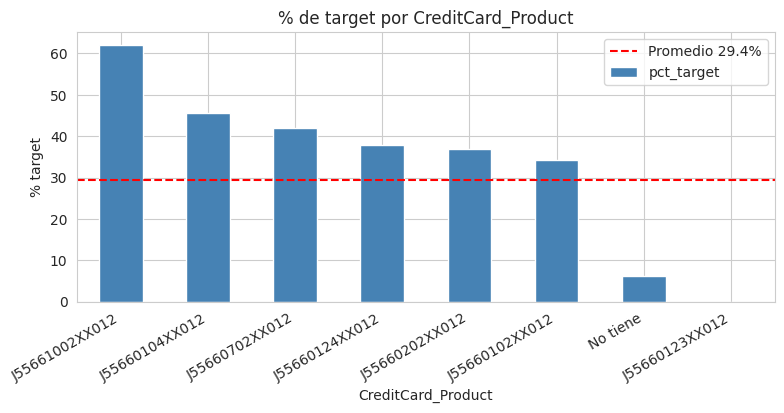

,clientes,tgt,pct_target
CreditCard_Product,,,
J55661002XX012,58,36,62.068966
J55660104XX012,8508,3887,45.686413
J55660702XX012,248,104,41.935484
J55660124XX012,29,11,37.931034
J55660202XX012,5777,2134,36.939588
J55660102XX012,402,138,34.328358
No tiene,8168,513,6.280607
J55660123XX012,1,0,0.000000


In [58]:
t = tabla_target(cat, 'CreditCard_Product')
grafico_target(t, 'CreditCard_Product')
t

Categorías agrupadas en "Otras": ['J55660702XX012', 'J55661002XX012', 'J55660124XX012', 'J55660123XX012']


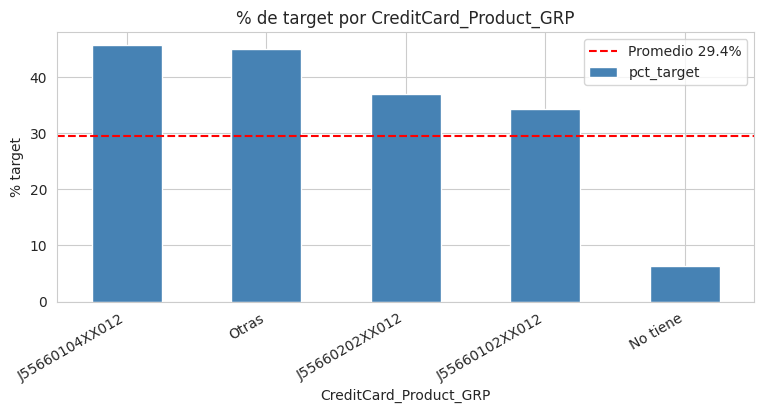

,clientes,tgt,pct_target
CreditCard_Product_GRP,,,
J55660104XX012,8508,3887,45.686413
Otras,336,151,44.940476
J55660202XX012,5777,2134,36.939588
J55660102XX012,402,138,34.328358
No tiene,8168,513,6.280607


In [59]:
frec = cat['CreditCard_Product'].value_counts()
chicas = frec[frec < 300].index.tolist()
print('Categorías agrupadas en "Otras":', chicas)

cat['CreditCard_Product_GRP'] = np.where(cat['CreditCard_Product'].isin(chicas), 'Otras', cat['CreditCard_Product'])

t = tabla_target(cat, 'CreditCard_Product_GRP')
grafico_target(t, 'CreditCard_Product_GRP')
t

In [60]:
mapa_tarjeta = t['pct_target'].to_dict()
cat['CreditCard_Product_pct_tgt'] = cat['CreditCard_Product_GRP'].map(mapa_tarjeta)
cat[['CreditCard_Product', 'CreditCard_Product_GRP', 'CreditCard_Product_pct_tgt']].drop_duplicates().sort_values('CreditCard_Product_pct_tgt')

,CreditCard_Product,CreditCard_Product_GRP,CreditCard_Product_pct_tgt
4,No tiene,No tiene,6.280607
19,J55660102XX012,J55660102XX012,34.328358
0,J55660202XX012,J55660202XX012,36.939588
114,J55660702XX012,Otras,44.940476
947,J55661002XX012,Otras,44.940476
190,J55660124XX012,Otras,44.940476
12840,J55660123XX012,Otras,44.940476
2,J55660104XX012,J55660104XX012,45.686413


- Los clientes sin tarjeta casi no compran (6%), mientras que los que tienen la tarjeta J55660104XX012 compran en 46% de los casos, muy por encima del promedio (29%).

### 5.2 Región: % de target

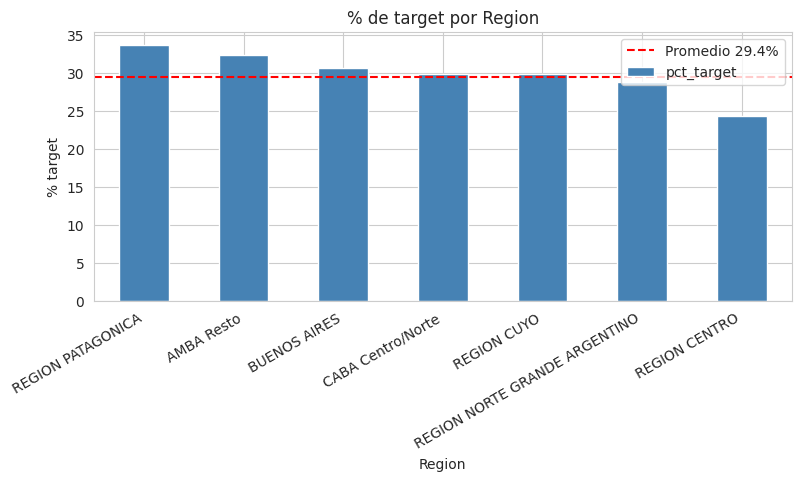

,clientes,tgt,pct_target
Region,,,
REGION PATAGONICA,2432,820,33.717105
AMBA Resto,1828,592,32.385120
BUENOS AIRES,6990,2138,30.586552
CABA Centro/Norte,2048,612,29.882812
REGION CUYO,1640,489,29.817073
REGION NORTE GRANDE ARGENTINO,3674,1056,28.742515
REGION CENTRO,4579,1116,24.372134


In [61]:
t = tabla_target(cat, 'Region')
grafico_target(t, 'Region')
t

In [62]:
mapa_region = t['pct_target'].to_dict()
cat['Region_pct_tgt'] = cat['Region'].map(mapa_region)
cat[['Region', 'Region_pct_tgt']].drop_duplicates().sort_values('Region_pct_tgt')

,Region,Region_pct_tgt
1,REGION CENTRO,24.372134
4,REGION NORTE GRANDE ARGENTINO,28.742515
3,REGION CUYO,29.817073
13,CABA Centro/Norte,29.882812
0,BUENOS AIRES,30.586552
18,AMBA Resto,32.385120
7,REGION PATAGONICA,33.717105


- Las diferencias entre regiones son más chicas que en tipo de tarjeta, van de 24% (Región Centro) a 34% (Patagonia y AMBA Resto). La variable aporta algo de información, pero mucho menos que la tarjeta.

### 5.3 Rango de edad: codificación ordinal + bines

- Esta variable tiene un orden natural, así que se puede pasar a número respetando el orden.

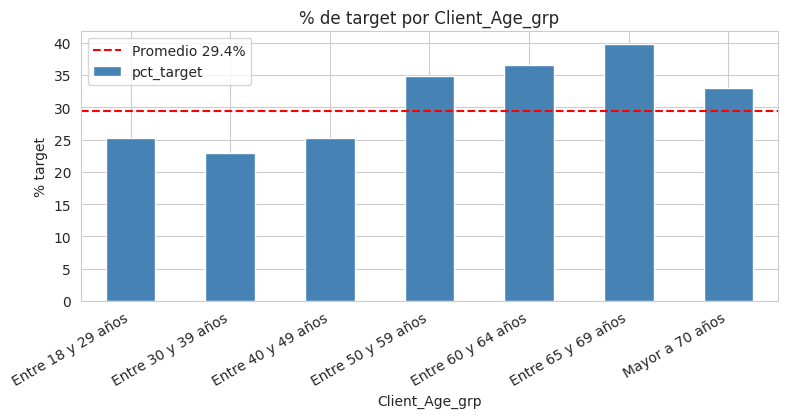

,clientes,tgt,pct_target
Client_Age_grp,,,
Entre 18 y 29 años,989,249,25.176946
Entre 30 y 39 años,5308,1214,22.871138
Entre 40 y 49 años,6563,1660,25.293311
Entre 50 y 59 años,5149,1796,34.880559
Entre 60 y 64 años,2122,776,36.569274
Entre 65 y 69 años,1745,694,39.770774
Mayor a 70 años,1315,434,33.003802


In [63]:
orden_edad = {'Menor a 18 años': 0, 'Entre 18 y 29 años': 1, 'Entre 30 y 39 años': 2, 'Entre 40 y 49 años': 3,
              'Entre 50 y 59 años': 4, 'Entre 60 y 64 años': 5, 'Entre 65 y 69 años': 6, 'Mayor a 70 años': 7}
cat['Client_Age_ord'] = cat['Client_Age_grp'].map(orden_edad)

t = tabla_target(cat, 'Client_Age_grp').sort_index(key=lambda x: x.map(orden_edad))
grafico_target(t, 'Client_Age_grp')
t

El % de target sube con la edad: los menores de 50 estan por debajo del promedio y los de 50 o más por encima. Con eso armo 3 bines que agrupan rangos de comportamiento parecido:
- Hasta 49 años
- 50 a 59 años
- 60 años o mas

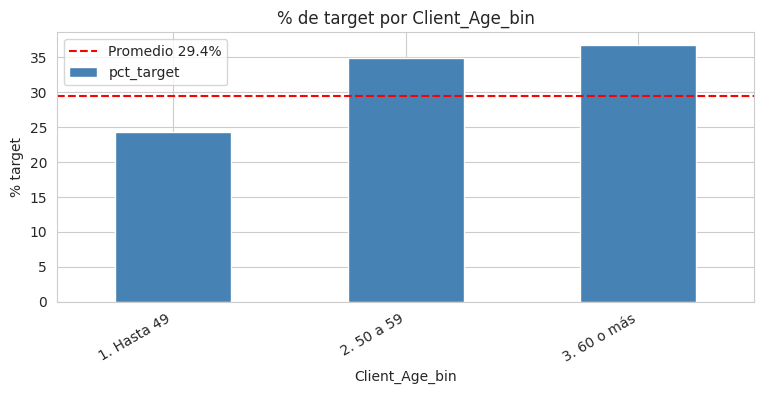

,clientes,tgt,pct_target
Client_Age_bin,,,
1. Hasta 49,12860,3123,24.284603
2. 50 a 59,5149,1796,34.880559
3. 60 o más,5182,1904,36.742570


In [64]:
bines_edad = {'Menor a 18 años': '1. Hasta 49', 'Entre 18 y 29 años': '1. Hasta 49', 'Entre 30 y 39 años': '1. Hasta 49',
              'Entre 40 y 49 años': '1. Hasta 49', 'Entre 50 y 59 años': '2. 50 a 59',
              'Entre 60 y 64 años': '3. 60 o más', 'Entre 65 y 69 años': '3. 60 o más', 'Mayor a 70 años': '3. 60 o más'}
cat['Client_Age_bin'] = cat['Client_Age_grp'].map(bines_edad)

t = tabla_target(cat, 'Client_Age_bin').sort_index()
grafico_target(t, 'Client_Age_bin')
t

In [65]:
cat['Client_Age_bin_ord'] = cat['Client_Age_bin'].str[0].astype(int)
cat['Client_Age_pct_tgt'] = cat['Client_Age_bin'].map(t['pct_target'])
cat[['Client_Age_grp', 'Client_Age_ord', 'Client_Age_bin', 'Client_Age_bin_ord', 'Client_Age_pct_tgt']].drop_duplicates().sort_values('Client_Age_ord')

,Client_Age_grp,Client_Age_ord,Client_Age_bin,Client_Age_bin_ord,Client_Age_pct_tgt
8,Entre 18 y 29 años,1,1. Hasta 49,1,24.284603
1,Entre 30 y 39 años,2,1. Hasta 49,1,24.284603
0,Entre 40 y 49 años,3,1. Hasta 49,1,24.284603
5,Entre 50 y 59 años,4,2. 50 a 59,2,34.880559
12,Entre 60 y 64 años,5,3. 60 o más,3,36.742570
2,Entre 65 y 69 años,6,3. 60 o más,3,36.742570
22,Mayor a 70 años,7,3. 60 o más,3,36.742570


### 5.4 Sexo: One Hot Encoding

One Hot Encoding crea una columna 0 o 1 por cada categoria. Funciona bien para variables con pocas categorias, con muchas categorías como tipo de tarjeta generaria muchas columnas.

In [66]:
t = tabla_target(cat, 'Sex')
print(t, '\n')

ohe = pd.get_dummies(cat[['client_id', 'Sex']], columns=['Sex'], prefix_sep='_dummy_', drop_first=True, dtype=int)
cat = cat.merge(ohe, how='left', on='client_id')
cat[['Sex', 'Sex_dummy_M']].value_counts()

     clientes   tgt  pct_target
Sex                            
M       13301  3979   29.915044
F        9890  2844   28.756320 



,,count
Sex,Sex_dummy_M,
M,1,13301
F,0,9890


La diferencia de % de target entre hombres y mujeres es chica, así que esta variable aporta poco al modelo.

In [67]:
cat_features = cat[['client_id',
                    'CreditCard_Product_pct_tgt',
                    'Region_pct_tgt',
                    'Client_Age_ord', 'Client_Age_bin_ord', 'Client_Age_pct_tgt',
                    'Sex_dummy_M']]
cat_features.head()

,client_id,CreditCard_Product_pct_tgt,Region_pct_tgt,Client_Age_ord,Client_Age_bin_ord,Client_Age_pct_tgt,Sex_dummy_M
0,4221845,36.939588,30.586552,3,1,24.284603,0
1,7219504,36.939588,24.372134,2,1,24.284603,0
2,5882370,45.686413,30.586552,6,3,36.742570,0
3,1158013,45.686413,29.817073,3,1,24.284603,1
4,3914580,6.280607,28.742515,2,1,24.284603,0


## 6. ABT final

Uno todo por `client_id`, partiendo del universo (una fila por cliente con su target).

In [68]:
ABT = universo[['client_id', 'TGT']]\
        .merge(identity_features.drop(['Sex', 'Client_Age_grp'], axis=1), how='left', on='client_id')\
        .merge(transform_features, how='left', on='client_id')\
        .merge(agg_features, how='left', on='client_id')\
        .merge(cat_features, how='left', on='client_id')

print('ABT:', ABT.shape)
print('Clientes únicos:', ABT['client_id'].nunique())

ABT: (23191, 694)
Clientes únicos: 23191


In [69]:
nulos_abt = ABT.isnull().sum()
print('Columnas con nulos:', (nulos_abt > 0).sum())
nulos_abt[nulos_abt > 0].sort_values(ascending=False).head(10)

Columnas con nulos: 0


,0


No quedan nulos, igual por seguridad se completa con 0 cualquier nulo o infinito que pudiera aparecer (por ejemplo, por divisiones por cero en los ratios) y elimino las variables constantes que no aportan informacion

In [70]:
ABT = ABT.fillna(0)
ABT = ABT.replace([np.inf, -np.inf], 0)

# Elimino variables constantes (un solo valor): no aportan informacion
# Ej.: ningún cliente del universo tiene seguros, así que esas columnas valen siempre 0
constantes = [c for c in ABT.columns if ABT[c].nunique() == 1]
print('Variables constantes eliminadas:', len(constantes))
print(constantes)
ABT = ABT.drop(columns=constantes)

print('\nABT final:', ABT.shape)
print('Nulos:', ABT.isnull().sum().sum())

Variables constantes eliminadas: 7
['Insurance_Life', 'Insurance_Home', 'Insurance_Accidents', 'Insurance_Mobile', 'Insurance_ATM', 'Insurance_Unemployment', 'Active_Insurance']

ABT final: (23191, 687)
Nulos: 0


In [71]:
resumen = pd.Series({
    'Clientes (filas)': ABT.shape[0],
    'Variables (sin client_id y TGT)': ABT.shape[1] - 2,
    'Tasa de target': f"{ABT['TGT'].mean():.1%}",
})
resumen.to_frame('ABT')

,ABT
Clientes (filas),23191
Variables (sin client_id y TGT),685
Tasa de target,29.4%


In [72]:
ABT.head()

,client_id,TGT,SavingAccount_Balance_Average,CreditCard_Total_Limit,Investment_Numbers,CreditCard_Premium,CreditCard_Active,Loan_Active,Mortgage_Active,SavingAccount_Active_ARG_Salary,...,CreditCard_Balance_DOLLAR_2vs5_rel,CreditCard_Revolving_2vs5_rel,CreditCard_Payment_Aut_Debit_2vs5_rel,CreditCard_Payment_External_2vs5_rel,CreditCard_Product_pct_tgt,Region_pct_tgt,Client_Age_ord,Client_Age_bin_ord,Client_Age_pct_tgt,Sex_dummy_M
0,4221845,0,0.00,48000.0,0.0,0,1,0,0,0,...,0.0,0.000000,0.0,0.0,36.939588,30.586552,3,1,24.284603,0
1,7219504,0,1137.43,0.0,0.0,0,1,1,0,0,...,0.0,0.000000,0.0,0.0,36.939588,24.372134,2,1,24.284603,0
2,5882370,0,0.00,48000.0,0.0,1,1,0,0,0,...,0.0,1.116600,0.0,0.0,45.686413,30.586552,6,3,36.742570,0
3,1158013,0,0.00,32000.0,0.0,0,1,0,0,0,...,1.0,16.340284,0.0,0.0,45.686413,29.817073,3,1,24.284603,1
4,3914580,0,545.98,0.0,0.0,0,0,0,0,0,...,0.0,0.000000,0.0,0.0,6.280607,28.742515,2,1,24.284603,0


## Conclusiones

- Universo: clientes presentes los 9 meses, sin paquete y sin tarjeta co-branding en enero 2019. Target: compra del producto (`Target = 1`) en marzo o abril 2019. Tasa de target de 29%.
- Nulos: solo 3 variables tenían nulos. El saldo promedio se reconstruyo con otras variables del mismo mes. Region y Tipo de Tarjeta estaban vacías en toda la historia y se completaron con los meses futuros (marzo/abril), usando `No tiene` si no tiene tarjeta activa y la categoría mas popular para los pocos casos sin dato.
- Outliers: las 4 variables de montos tenían colas largas a la derecha. Se recortaron en el p99 de los valores positivos para corregir los extremos sin eliminar clientes.
- ABT: una fila por cliente con identity, transform y aggregate features (30 variables agregadas en ventanas de 6 y 3 meses, mas variaciones entre meses, sin reducción de variables y sin nulos.
- Categoricas: el tipo de tarjeta es la categórica mas discriminante (de 6% de target para clientes sin tarjeta a 46% para la tarjeta más comun). La edad muestra una relación creciente con el target. Region y sexo discriminan poco.

---

# Parte 2 – Modelo (TP grupal)
A partir de la ABT del TP individual (arriba) entrenamos el modelo. Las secciones 1 (universo y target) y 2 (proceso: nulos, outliers, ABT y categóricas)
de la consigna son las del TP individual; acá seguimos el proceso con la separación train/test y la reducción de variables, y después
performance, feature importance, hiperparámetros, conclusiones y la simulación de campaña.

In [73]:
import lightgbm as lgb
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score

AZUL, NARANJA, GRIS = '#2a78d6', '#eb6834', '#8a8984'
SEMILLA = 42
TASA_BASE = ABT['TGT'].mean()
print('LightGBM', lgb.__version__, '| ABT de partida:', ABT.shape, f'| tasa de target {TASA_BASE:.1%}')

LightGBM 4.6.0 | ABT de partida: (23191, 687) | tasa de target 29.4%


## 2.7 Separación train / test (70 / 30)
El modelo aprende con el 70% de los clientes (**train**) y se evalúa con el 30% restante (**test**), clientes que nunca vio.
Es estratificado: las dos partes mantienen la misma tasa de compra.

In [74]:
train, test = train_test_split(ABT, test_size=0.3, random_state=SEMILLA, stratify=ABT['TGT'])
train, test = train.copy(), test.copy()
print(f'Train: {len(train):,} clientes, tasa {train.TGT.mean():.1%}')
print(f'Test:  {len(test):,} clientes, tasa {test.TGT.mean():.1%}')

Train: 16,233 clientes, tasa 29.4%
Test:  6,958 clientes, tasa 29.4%


### Recalculo del % de target solo con train
En el TP individual el % de target de tarjeta, región y edad se calculó con el 100% de los clientes (era lo pedido, porque no había modelo).
Ahora que hay un test, lo recalculamos **solo con train**: si no, esas variables ya "conocen" el resultado de los clientes de test
y el modelo parecería mejor de lo que es. Las categorías (bines) son las mismas del TP individual.

In [75]:
cat_cols = cat[['client_id', 'CreditCard_Product_GRP', 'Region', 'Client_Age_bin']]
train = train.merge(cat_cols, how='left', on='client_id')
test = test.merge(cat_cols, how='left', on='client_id')

comparacion = {}
for var, col in [('CreditCard_Product_GRP', 'CreditCard_Product_pct_tgt'),
                 ('Region', 'Region_pct_tgt'),
                 ('Client_Age_bin', 'Client_Age_pct_tgt')]:
    mapa = train.groupby(var)['TGT'].mean() * 100
    antes = train.groupby(var)[col].first()
    train[col] = train[var].map(mapa)
    test[col] = test[var].map(mapa).fillna(train['TGT'].mean() * 100)
    comparacion[var] = pd.DataFrame({'% target TP individual (100%)': antes, '% target solo train': mapa})

train = train.drop(columns=['CreditCard_Product_GRP', 'Region', 'Client_Age_bin'])
test = test.drop(columns=['CreditCard_Product_GRP', 'Region', 'Client_Age_bin'])

pd.concat(comparacion).round(1)

% target TP individual (100%)  \
CreditCard_Product_GRP J55660102XX012                                          34.3   
                       J55660104XX012                                          45.7   
                       J55660202XX012                                          36.9   
                       No tiene                                                 6.3   
                       Otras                                                   44.9   
Region                 AMBA Resto                                              32.4   
                       BUENOS AIRES                                            30.6   
                       CABA Centro/Norte                                       29.9   
                       REGION CENTRO                                           24.4   
                       REGION CUYO                                             29.8   
                       REGION NORTE GRANDE ARGENTINO                           28.7   
                       REGION PATAGONICA                                       33.7   
Client_Age_bin         1. Hasta 49                                             24.3   
                       2. 50 a 59                                              34.9   
                       3. 60 o más                                             36.7   

                                                      % target solo train  
CreditCard_Product_GRP J55660102XX012                                34.0  
                       J55660104XX012                                45.4  
                       J55660202XX012                                37.1  
                       No tiene                                       6.3  
                       Otras                                         46.8  
Region                 AMBA Resto                                    31.5  
                       BUENOS AIRES                                  30.7  
                       CABA Centro/Norte                             30.7  
                       REGION CENTRO                                 24.2  
                       REGION CUYO                                   29.5  
                       REGION NORTE GRANDE ARGENTINO                 28.8  
                       REGION PATAGONICA                             33.9  
Client_Age_bin         1. Hasta 49                                   24.3  
                       2. 50 a 59                                    35.1  
                       3. 60 o más                                   36.6

## 2.8 Reducción de variables
1. **Constantes**: variables con un único valor (por ejemplo, ningún cliente del universo tiene seguros).
1. Las constantes ya se sacaron en el TP individual; se vuelve a chequear por si acaso.
2. **Correlacionadas**: si dos variables tienen correlación mayor a 0,80 se queda una sola (mismo criterio que en clase). Se calcula con train.

In [76]:
features = [c for c in train.columns if c not in ['client_id', 'TGT']]
print('Variables iniciales:', len(features))

constantes = [c for c in features if train[c].nunique() == 1]
features = [c for c in features if c not in constantes]
print('Constantes eliminadas:', len(constantes), '->', len(features))

corr = train[features].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).fillna(0)
correlacionadas = [c for c in upper.columns if (upper[c] > 0.80).any()]
features = [c for c in features if c not in correlacionadas]
print('Correlacionadas eliminadas:', len(correlacionadas), '->', len(features))

Variables iniciales: 685
Constantes eliminadas: 0 -> 685
Correlacionadas eliminadas: 457 -> 228


## 2.9 Primer modelo con todas las variables → selección por importancia
Entrenamos un LightGBM rápido con todas las variables que quedaron, miramos cuáles usa más y probamos quedarnos con las top 10, 15, 20, 30 y 50.
Elegimos la cantidad comparando el AUC con **validación cruzada dentro de train** (test se reserva para la evaluación final).

In [77]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMILLA)

modelo_inicial = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15, min_child_samples=500,
                                    subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                    random_state=SEMILLA, verbose=-1)
modelo_inicial.fit(train[features], train['TGT'])
imp_inicial = pd.Series(modelo_inicial.booster_.feature_importance(importance_type='gain'), index=features)\
                .sort_values(ascending=False)
print(f'AUC CV con las {len(features)} variables:',
      round(cross_val_score(modelo_inicial, train[features], train['TGT'], cv=cv, scoring='roc_auc').mean(), 4))

resultados_n = {}
for n in [5, 10, 15, 20, 30, 50]:
    top = imp_inicial.index[:n].tolist()
    resultados_n[n] = cross_val_score(modelo_inicial, train[top], train['TGT'], cv=cv, scoring='roc_auc').mean()
pd.Series(resultados_n, name='AUC CV (train)').to_frame().round(4)

AUC CV con las 228 variables: 0.8374


,AUC CV (train)
5,0.8171
10,0.8263
15,0.8312
20,0.8328
30,0.8381
50,0.8377


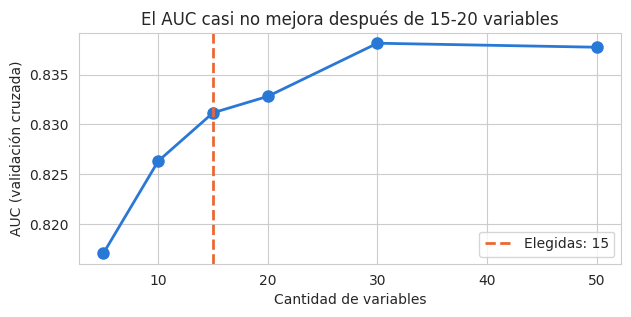

['CreditCard_Active',
 'CreditCard_Total_Spending_0vs5_rel',
 'SavingAccount_Salary_Payment_Amount_sum_u6m',
 'SavingAccount_Total_Amount_sum_u6m',
 'Client_Age_ord',
 'Operations_Bank_sum_u6m',
 'SavingAccount_Salary_Payment_Amount_0vs2_rel',
 'SavingAccount_Balance_Average_no_cero_u6m',
 'Month_Last_product_Months',
 'SavingAccount_Salary_Payment_Amount_0vs5_rel',
 'SavingAccount_Active_ARG_Salary',
 'CreditCard_Total_Limit',
 'Loan_Active',
 'CreditCard_Revolving_min_u6m',
 'SavingAccount_Balance_Average']

In [78]:
# Elegimos 15: pasar de 15 a 30 variables mejora el AUC en menos de 0,01 y duplica lo que hay que explicar y mantener.
N_VARIABLES = 15
vars_modelo = imp_inicial.index[:N_VARIABLES].tolist()

fig, ax = plt.subplots(figsize=(7, 3))
s = pd.Series(resultados_n)
ax.plot(s.index, s.values, marker='o', color=AZUL, linewidth=2, markersize=8)
ax.axvline(N_VARIABLES, color=NARANJA, linestyle='--', linewidth=2, label=f'Elegidas: {N_VARIABLES}')
ax.set_xlabel('Cantidad de variables'); ax.set_ylabel('AUC (validación cruzada)'); ax.legend()
ax.set_title('El AUC casi no mejora después de 15-20 variables')
plt.show()
vars_modelo

# 5. Hiperparámetros y modelo final
*(Va antes que la performance porque primero hay que tener el modelo; en la presentación se muestra en el orden de la consigna.)*

Buscamos la mejor combinación de hiperparámetros con `RandomizedSearchCV`: prueba 50 combinaciones al azar de la grilla y evalúa cada una con
validación cruzada estratificada de 3 partes sobre train. Métrica: AUC.

In [79]:
param_test = {'num_leaves': np.arange(4, 32, 2),
              'max_depth': np.arange(3, 9, 1),
              'min_child_samples': [200, 500, 1000, 1500, 2000],
              'n_estimators': [100, 200, 300, 400, 600],
              'learning_rate': [0.01, 0.03, 0.05, 0.1],
              'subsample': [0.7, 0.8, 1.0],
              'colsample_bytree': [0.7, 0.8, 1.0],
              'reg_lambda': [0, 1, 5, 10]}

clf = lgb.LGBMClassifier(subsample_freq=1, random_state=SEMILLA, verbose=-1, n_jobs=4)
gs = RandomizedSearchCV(estimator=clf, param_distributions=param_test, n_iter=50, scoring='roc_auc',
                        cv=cv, refit=True, random_state=SEMILLA, verbose=1, return_train_score=True)
gs.fit(train[vars_modelo], train['TGT'])

print(f'\nMejor AUC en validación cruzada: {gs.best_score_:.4f}')
pd.Series(gs.best_params_, name='valor elegido').to_frame()

Fitting 3 folds for each of 50 candidates, totalling 150 fits

Mejor AUC en validación cruzada: 0.8341


,valor elegido
subsample,0.8
reg_lambda,5.0
num_leaves,24.0
n_estimators,100.0
min_child_samples,500.0
max_depth,3.0
learning_rate,0.1
colsample_bytree,1.0


In [80]:
# Top 5 combinaciones probadas
res = pd.DataFrame(gs.cv_results_)
cols_res = ['param_' + p for p in param_test] + ['mean_train_score', 'mean_test_score']
res.sort_values('mean_test_score', ascending=False)[cols_res].head(5).rename(
    columns={'mean_train_score': 'AUC train', 'mean_test_score': 'AUC validación'}).round(4)

,param_num_leaves,param_max_depth,param_min_child_samples,param_n_estimators,param_learning_rate,param_subsample,param_colsample_bytree,param_reg_lambda,AUC train,AUC validación
12,24,3,500,100,0.10,0.8,1.0,5,0.8452,0.8341
46,22,7,500,100,0.05,0.7,0.7,0,0.8451,0.8340
42,14,6,200,200,0.03,0.8,1.0,0,0.8562,0.8336
27,28,4,200,200,0.03,1.0,0.8,10,0.8490,0.8335
7,22,4,200,200,0.05,0.8,0.7,10,0.8538,0.8335


In [81]:
modelo_final = gs.best_estimator_
print(modelo_final)

LGBMClassifier(max_depth=np.int64(3), min_child_samples=500, n_jobs=4,
               num_leaves=np.int64(24), random_state=42, reg_lambda=5,
               subsample=0.8, subsample_freq=1, verbose=-1)


# 3. Performance del modelo

## 3.1 AUC en train y en test
El **AUC** mide qué tan bien el modelo ordena a los clientes: es la probabilidad de que, tomando un comprador y un no comprador al azar, el modelo
le dé más score al comprador. 0,5 = azar, 1 = perfecto. Que train y test den parecido indica que el modelo **no está sobreajustado**.

AUC train: 0.8441
AUC test:  0.8400
Diferencia: 0.0041


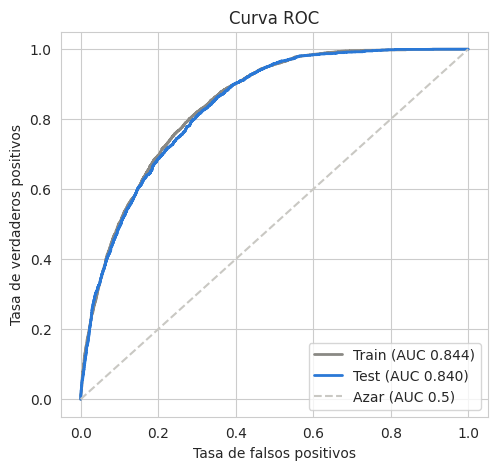

In [82]:
train['score'] = modelo_final.predict_proba(train[vars_modelo])[:, 1]
test['score'] = modelo_final.predict_proba(test[vars_modelo])[:, 1]

auc_train = roc_auc_score(train['TGT'], train['score'])
auc_test = roc_auc_score(test['TGT'], test['score'])
print(f'AUC train: {auc_train:.4f}')
print(f'AUC test:  {auc_test:.4f}')
print(f'Diferencia: {auc_train - auc_test:.4f}')

fig, ax = plt.subplots(figsize=(5.5, 5))
for df, nombre, color in [(train, 'Train', GRIS), (test, 'Test', AZUL)]:
    fpr, tpr, _ = roc_curve(df['TGT'], df['score'])
    ax.plot(fpr, tpr, color=color, linewidth=2, label=f'{nombre} (AUC {roc_auc_score(df.TGT, df.score):.3f})')
ax.plot([0, 1], [0, 1], color='#c9c8c3', linestyle='--', label='Azar (AUC 0.5)')
ax.set_xlabel('Tasa de falsos positivos'); ax.set_ylabel('Tasa de verdaderos positivos'); ax.set_title('Curva ROC'); ax.legend()
plt.show()

## 3.2 Matriz de confusión
Con un corte de probabilidad decidimos a quién "predecimos" como comprador. Con el corte por defecto (0,5) el modelo es conservador;
bajando el corte encontramos más compradores a cambio de contactar a más gente. Para Marketing es más útil pensar en **deciles** (siguiente punto).

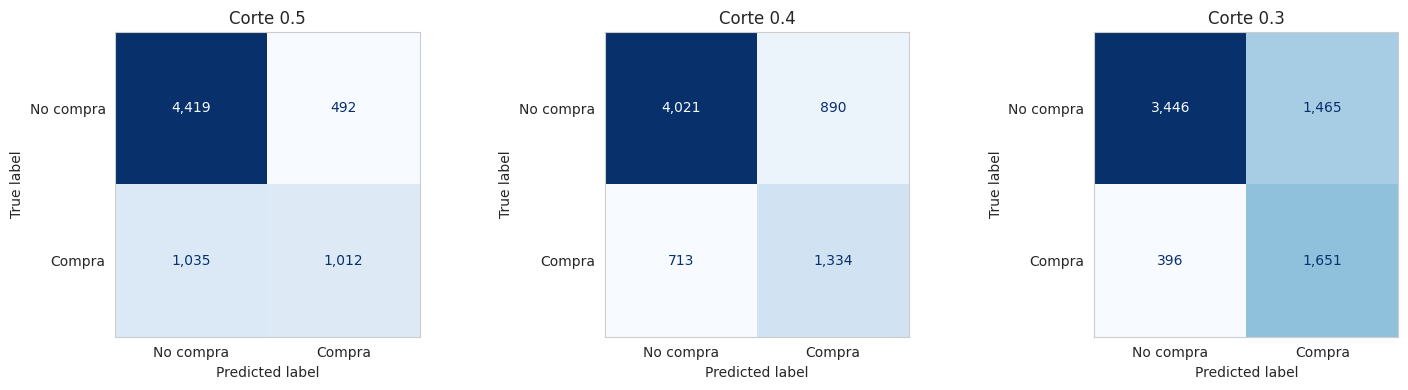

,0.5,0.4,0.3
Accuracy,0.781,0.770,0.733
"Precisión (de los contactados, % que compra)",0.673,0.600,0.530
Recall (% de compradores encontrados),0.494,0.652,0.807
% de la base contactada,0.216,0.320,0.448


In [83]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
metricas_corte = {}
for ax, corte in zip(axes, [0.5, 0.4, 0.3]):
    y_pred = (test['score'] > corte).astype(int)
    cm = confusion_matrix(test['TGT'], y_pred)
    ConfusionMatrixDisplay(cm, display_labels=['No compra', 'Compra']).plot(ax=ax, cmap='Blues', colorbar=False, values_format=',')
    ax.set_title(f'Corte {corte}'); ax.grid(False)
    metricas_corte[corte] = {'Accuracy': accuracy_score(test.TGT, y_pred),
                             'Precisión (de los contactados, % que compra)': precision_score(test.TGT, y_pred),
                             'Recall (% de compradores encontrados)': recall_score(test.TGT, y_pred),
                             '% de la base contactada': y_pred.mean()}
plt.tight_layout(); plt.show()
pd.DataFrame(metricas_corte).round(3)

## 3.3 Tabla de deciles y Lift
Ordenamos a los clientes por score y los dividimos en 10 grupos iguales. Los **cortes de los deciles se calculan en train y se aplican a test**
(como en clase), así medimos cómo funcionaría el modelo con clientes nuevos.

- **% compra**: tasa de compra dentro del decil.
- **Lift**: cuántas veces mejor que contactar al azar. Lift 2 = el decil compra el doble que el promedio. (Referencia de clase: 2 bien, 2,5 bastante bien, 3 excelente.)
- **% compradores acumulado**: qué parte de todos los compradores capturamos si contactamos hasta ese decil.

In [84]:
# Cortes de deciles definidos en train
cortes = np.quantile(train['score'], np.linspace(0, 1, 11))
cortes[0], cortes[-1] = -np.inf, np.inf

def asignar_decil(score):
    # decil 1 = score más alto
    return 10 - pd.cut(score, bins=cortes, labels=False, include_lowest=True)

train['decil'] = asignar_decil(train['score'])
test['decil'] = asignar_decil(test['score'])

def tabla_deciles(df):
    t = df.groupby('decil').agg(clientes=('TGT', 'size'), compradores=('TGT', 'sum'),
                                score_min=('score', 'min'), score_max=('score', 'max'))
    t['% compra'] = t['compradores'] / t['clientes'] * 100
    t['Lift'] = t['% compra'] / (df['TGT'].mean() * 100)
    t['% clientes acum'] = t['clientes'].cumsum() / t['clientes'].sum() * 100
    t['% compradores acum'] = t['compradores'].cumsum() / t['compradores'].sum() * 100
    t['Lift acum'] = (t['compradores'].cumsum() / t['clientes'].cumsum()) / df['TGT'].mean()
    return t.round(2)

print('TRAIN'); display(tabla_deciles(train))
print('TEST');  tabla_test = tabla_deciles(test); display(tabla_test)

TRAIN


,clientes,compradores,score_min,score_max,% compra,Lift,% clientes acum,% compradores acum,Lift acum
decil,,,,,,,,,
1,1624,1242,0.66,0.92,76.48,2.60,10.0,26.01,2.60
2,1623,1006,0.53,0.66,61.98,2.11,20.0,47.07,2.35
3,1623,768,0.43,0.53,47.32,1.61,30.0,63.15,2.10
4,1623,633,0.35,0.43,39.00,1.33,40.0,76.40,1.91
5,1623,482,0.27,0.35,29.70,1.01,50.0,86.49,1.73
6,1624,357,0.18,0.27,21.98,0.75,60.0,93.97,1.57
7,1623,204,0.08,0.18,12.57,0.43,70.0,98.24,1.40
8,1623,65,0.02,0.08,4.00,0.14,80.0,99.60,1.25
9,1623,16,0.01,0.02,0.99,0.03,90.0,99.94,1.11


TEST


,clientes,compradores,score_min,score_max,% compra,Lift,% clientes acum,% compradores acum,Lift acum
decil,,,,,,,,,
1,660,517,0.66,0.92,78.33,2.66,9.49,25.26,2.66
2,641,384,0.53,0.66,59.91,2.04,18.70,44.02,2.35
3,714,352,0.43,0.53,49.30,1.68,28.96,61.21,2.11
4,666,250,0.35,0.43,37.54,1.28,38.53,73.42,1.91
5,729,235,0.27,0.35,32.24,1.10,49.01,84.90,1.73
6,713,171,0.18,0.27,23.98,0.82,59.26,93.26,1.57
7,714,100,0.08,0.18,14.01,0.48,69.52,98.14,1.41
8,707,23,0.02,0.08,3.25,0.11,79.68,99.27,1.25
9,679,14,0.01,0.02,2.06,0.07,89.44,99.95,1.12


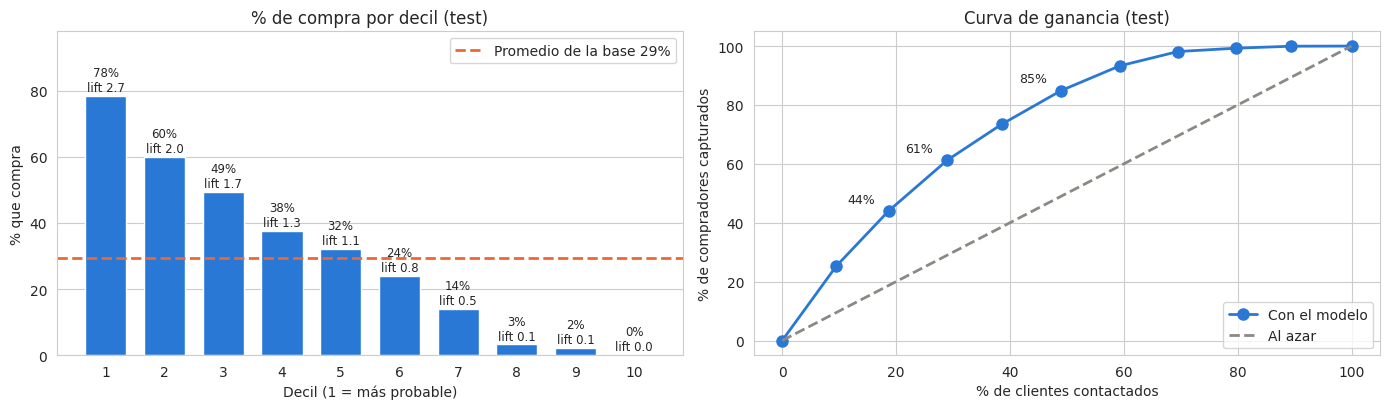

In [85]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))

ax = axes[0]
ax.bar(tabla_test.index, tabla_test['% compra'], color=AZUL, width=0.7)
ax.axhline(TASA_BASE * 100, color=NARANJA, linestyle='--', linewidth=2, label=f'Promedio de la base {TASA_BASE:.0%}')
for d, v, l in zip(tabla_test.index, tabla_test['% compra'], tabla_test['Lift']):
    ax.text(d, v + 1.5, f'{v:.0f}%\nlift {l:.1f}', ha='center', fontsize=8.5)
ax.set_xticks(range(1, 11)); ax.set_xlabel('Decil (1 = más probable)'); ax.set_ylabel('% que compra')
ax.set_ylim(0, tabla_test['% compra'].max() * 1.25); ax.set_title('% de compra por decil (test)'); ax.legend(); ax.grid(axis='x', visible=False)

ax = axes[1]
x = np.r_[0, tabla_test['% clientes acum']]
y = np.r_[0, tabla_test['% compradores acum']]
ax.plot(x, y, marker='o', color=AZUL, linewidth=2, markersize=8, label='Con el modelo')
ax.plot([0, 100], [0, 100], color=GRIS, linestyle='--', linewidth=2, label='Al azar')
for xi, yi in zip(x[[2, 3, 5]], y[[2, 3, 5]]):
    ax.annotate(f'{yi:.0f}%', (xi, yi), textcoords='offset points', xytext=(-30, 6), fontsize=9)
ax.set_xlabel('% de clientes contactados'); ax.set_ylabel('% de compradores capturados')
ax.set_title('Curva de ganancia (test)'); ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

# 4. Feature importance y análisis de las variables top

## 4.1 Importancia de las variables
- **Gain**: cuánto mejora el modelo cada vez que usa la variable (la más interpretable).
- **Split**: cuántas veces la usa para cortar en los árboles.

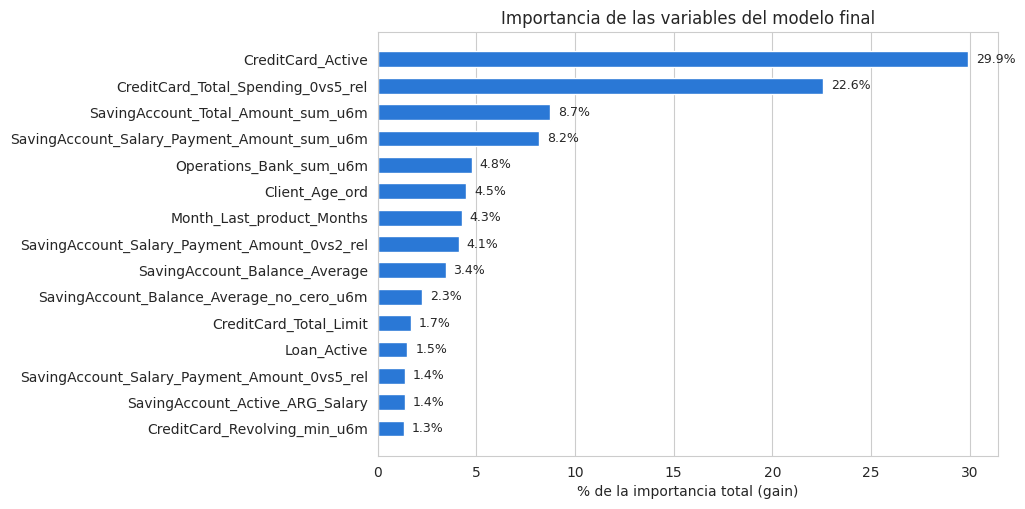

,gain,split,% gain
CreditCard_Active,7358.0,42,29.9
CreditCard_Total_Spending_0vs5_rel,5547.9,67,22.6
SavingAccount_Total_Amount_sum_u6m,2147.6,35,8.7
SavingAccount_Salary_Payment_Amount_sum_u6m,2015.0,27,8.2
Operations_Bank_sum_u6m,1173.3,31,4.8
Client_Age_ord,1102.0,55,4.5
Month_Last_product_Months,1047.8,59,4.3
SavingAccount_Salary_Payment_Amount_0vs2_rel,1009.5,24,4.1
SavingAccount_Balance_Average,846.7,54,3.4
SavingAccount_Balance_Average_no_cero_u6m,554.1,3,2.3


In [86]:
imp = pd.DataFrame({'gain': modelo_final.booster_.feature_importance(importance_type='gain'),
                    'split': modelo_final.booster_.feature_importance(importance_type='split')}, index=vars_modelo)
imp['% gain'] = imp['gain'] / imp['gain'].sum() * 100
imp = imp.sort_values('% gain', ascending=False)

fig, ax = plt.subplots(figsize=(8, 5.5))
s = imp['% gain'].sort_values()
ax.barh(s.index, s.values, color=AZUL, height=0.6)
for i, v in enumerate(s.values):
    ax.text(v + 0.4, i, f'{v:.1f}%', va='center', fontsize=9)
ax.set_xlabel('% de la importancia total (gain)'); ax.set_title('Importancia de las variables del modelo final'); ax.grid(axis='y', visible=False)
plt.show()
imp.round(1)

### ¿Qué significa cada variable? (versión para Marketing)

In [87]:
descripcion = {
    'CreditCard_Active': 'Tiene tarjeta de crédito activa',
    'CreditCard_Total_Spending_0vs5_rel': 'Consumo con tarjeta en enero vs agosto (cuántas veces)',
    'SavingAccount_Total_Amount_sum_u6m': 'Plata total que movió en la caja de ahorro (6 meses)',
    'SavingAccount_Salary_Payment_Amount_sum_u6m': 'Sueldo cobrado en el banco (6 meses)',
    'CreditCard_Total_Spending_sum_u6m': 'Consumo total con tarjeta (6 meses)',
    'Operations_Bank_sum_u6m': 'Operaciones por caja en sucursal (6 meses)',
    'SavingAccount_Days_with_use_sum_u6m': 'Días con movimientos en la caja de ahorro (6 meses)',
    'Client_Age_ord': 'Rango de edad',
    'SavingAccount_Balance_Average_ene': 'Saldo promedio en caja de ahorro (enero)',
    'SavingAccount_Salary_Payment_Amount_0vs5_rel': 'Sueldo de enero vs agosto (cuántas veces)',
    'SavingAccount_Salary_Payment_Amount_0vs2_rel': 'Sueldo de enero vs noviembre (cuántas veces)',
    'Month_Last_product_Months': 'Meses desde que sacó su último producto',
    'CreditCard_Total_Limit_ene': 'Límite de la tarjeta (enero)',
    'Last_First_product_Months': 'Meses entre su primer y su último producto',
    'SavingAccount_Active_ARG': 'Tiene caja de ahorro en pesos',
    'CreditCard_Product_GRP_pct_tgt': 'Tipo de tarjeta (codificado con % de compra)',
    'CreditCard_Spending_Aut_Debits_0vs5_rel': 'Débitos automáticos en tarjeta, enero vs agosto (cuántas veces)',
    'Region_pct_tgt': 'Región (codificada con % de compra)',
    'CreditCard_Product_pct_tgt': 'Tipo de tarjeta (codificado con % de compra)',
    'Client_Age_pct_tgt': 'Rango de edad (codificado con % de compra)',
    'Client_Age_bin_ord': 'Rango de edad agrupado (hasta 49 / 50-59 / 60+)',
    'SavingAccount_Balance_Average': 'Saldo promedio en caja de ahorro (enero)',
    'CreditCard_Total_Limit': 'Límite de la tarjeta (enero)',
    'Investment_Numbers': 'Cantidad de inversiones (enero)',
    'Month_First_product_Months': 'Antigüedad como cliente (meses)',
    'Active_Products': 'Cantidad de productos activos',
    'SavingAccount_Credits_vs_Debits_Amounts': 'Ingresos vs egresos de la caja de ahorro (enero)',
}
imp_mkt = imp[['% gain']].copy()
imp_mkt.insert(0, 'qué mide', [descripcion.get(v, v) for v in imp_mkt.index])
imp_mkt.round(1)

,qué mide,% gain
CreditCard_Active,Tiene tarjeta de crédito activa,29.9
CreditCard_Total_Spending_0vs5_rel,Consumo con tarjeta en enero vs agosto (cuánta...,22.6
SavingAccount_Total_Amount_sum_u6m,Plata total que movió en la caja de ahorro (6 ...,8.7
SavingAccount_Salary_Payment_Amount_sum_u6m,Sueldo cobrado en el banco (6 meses),8.2
Operations_Bank_sum_u6m,Operaciones por caja en sucursal (6 meses),4.8
Client_Age_ord,Rango de edad,4.5
Month_Last_product_Months,Meses desde que sacó su último producto,4.3
SavingAccount_Salary_Payment_Amount_0vs2_rel,Sueldo de enero vs noviembre (cuántas veces),4.1
SavingAccount_Balance_Average,Saldo promedio en caja de ahorro (enero),3.4
SavingAccount_Balance_Average_no_cero_u6m,SavingAccount_Balance_Average_no_cero_u6m,2.3


## 4.2 Análisis de las variables top
Para cada variable importante dividimos a los clientes en grupos según su valor y miramos el **% de compra** de cada grupo (como `Graficar_Variables2` de clase).
Así vemos **en qué dirección** empuja cada variable: si los clientes con valores altos compran más o menos.

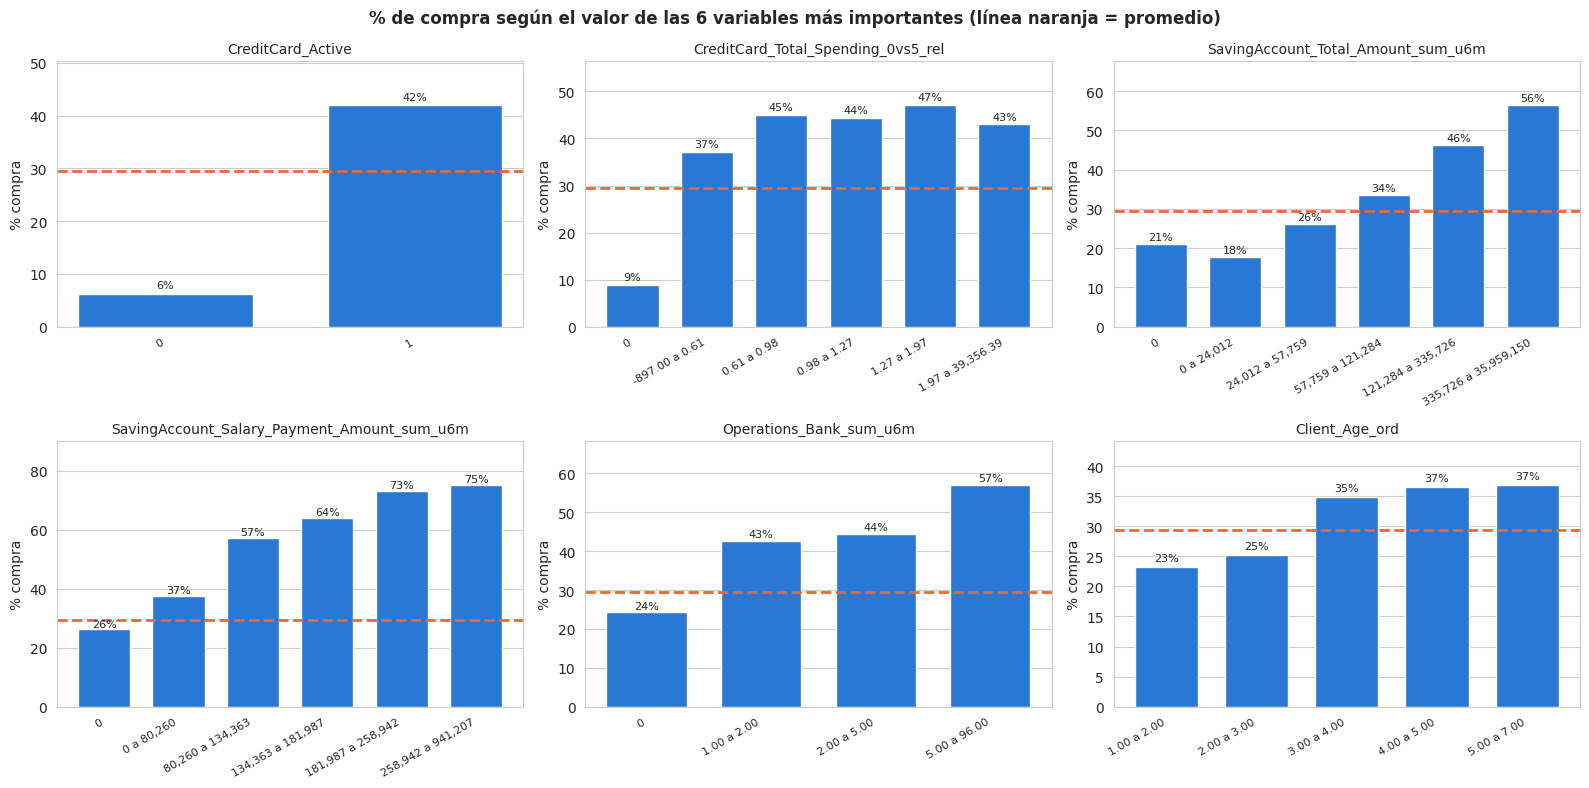

In [88]:
def perfil_variable(df, var, n_grupos=5):
    v = df[var]
    ceros = (v == 0)
    grupos = pd.Series(index=df.index, dtype=object)
    if ceros.mean() > 0.05:
        grupos[ceros] = '0'
        resto = v[~ceros]
    else:
        resto = v
    if resto.nunique() <= n_grupos:
        grupos[resto.index] = resto.round(2).astype(str)
    else:
        q = pd.qcut(resto, n_grupos, duplicates='drop')
        dec = 0 if resto.abs().median() >= 100 else 2
        etiqueta = lambda i: f'{i.left:,.{dec}f} a {i.right:,.{dec}f}'
        grupos[resto.index] = q.apply(etiqueta).astype(str)
        orden = ['0'] * int(ceros.any()) + [etiqueta(i) for i in q.cat.categories]
    t = df.groupby(grupos)['TGT'].agg(clientes='size', pct_compra='mean')
    t['pct_compra'] *= 100
    if resto.nunique() > n_grupos:
        t = t.reindex([o for o in orden if o in t.index])
    else:
        t = t.sort_index(key=lambda x: pd.to_numeric(x, errors='coerce'))
    return t

todos = pd.concat([train, test], ignore_index=True)
top_vars = imp.index[:6].tolist()
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
perfiles = {}
for ax, var in zip(axes.ravel(), top_vars):
    t = perfil_variable(todos, var)
    perfiles[var] = t
    ax.bar(range(len(t)), t['pct_compra'], color=AZUL, width=0.7)
    ax.axhline(TASA_BASE * 100, color=NARANJA, linestyle='--', linewidth=2)
    ax.set_xticks(range(len(t))); ax.set_xticklabels(t.index, rotation=30, ha='right', fontsize=8)
    ax.set_title(var, fontsize=10); ax.set_ylabel('% compra'); ax.grid(axis='x', visible=False)
    for i, v in enumerate(t['pct_compra']):
        ax.text(i, v + 1, f'{v:.0f}%', ha='center', fontsize=8)
    ax.set_ylim(0, t['pct_compra'].max() * 1.2)
fig.suptitle('% de compra según el valor de las 6 variables más importantes (línea naranja = promedio)', fontweight='bold')
plt.tight_layout(); plt.show()

In [89]:
for var, t in perfiles.items():
    print(f'\n--- {var}')
    print(t.round(1).to_string())


--- CreditCard_Active
   clientes  pct_compra
0      8168         6.3
1     15023        42.0

--- CreditCard_Total_Spending_0vs5_rel
                  clientes  pct_compra
0                     9377         8.9
-897.00 a 0.61        2763        37.1
0.61 a 0.98           2763        45.0
0.98 a 1.27           2762        44.4
1.27 a 1.97           2763        47.1
1.97 a 39,356.39      2763        43.0

--- SavingAccount_Total_Amount_sum_u6m
                      clientes  pct_compra
0                        10269        21.1
0 a 24,012                2585        17.7
24,012 a 57,759           2584        26.2
57,759 a 121,284          2584        33.7
121,284 a 335,726         2584        46.2
335,726 a 35,959,150      2585        56.4

--- SavingAccount_Salary_Payment_Amount_sum_u6m
                   clientes  pct_compra
0                     21056        26.2
0 a 80,260              427        37.5
80,260 a 134,363        427        57.4
134,363 a 181,987       427        63.9
18

## 4.3 Perfil del cliente: decil 1 vs decil 10
Comparamos el valor promedio de las variables del modelo entre los clientes con más y menos chances de compra.

In [90]:
perfil = todos.groupby('decil')[vars_modelo].mean().T[[1, 5, 10]]
perfil.columns = ['Decil 1 (más probable)', 'Decil 5', 'Decil 10 (menos probable)']
perfil.loc[imp.index].round(1)

,Decil 1 (más probable),Decil 5,Decil 10 (menos probable)
CreditCard_Active,1.0,1.0,0.0
CreditCard_Total_Spending_0vs5_rel,60.7,83.0,0.0
SavingAccount_Total_Amount_sum_u6m,755642.3,44181.1,593.6
SavingAccount_Salary_Payment_Amount_sum_u6m,116912.0,3831.0,10.3
Operations_Bank_sum_u6m,2.8,0.3,0.1
Client_Age_ord,3.9,3.9,3.0
Month_Last_product_Months,7.3,58.0,32.3
SavingAccount_Salary_Payment_Amount_0vs2_rel,1797.0,34.5,0.0
SavingAccount_Balance_Average,16965.3,971.7,6.1
SavingAccount_Balance_Average_no_cero_u6m,5.6,1.7,2.2


# 7. Adicional: simulación de campaña para Marketing

## 7.1 ¿Hasta qué decil conviene contactar?
Supuestos (los mismos del ejemplo de clase, se pueden cambiar en la celda):
- **Costo por contacto**: $10.000
- **Ganancia por cada venta**: $100.000

Simulamos la campaña sobre los clientes de test (que el modelo no vio) y la escalamos a todo el universo.

In [91]:
COSTO_CONTACTO = 10_000
GANANCIA_VENTA = 100_000

camp = tabla_test[['clientes', 'compradores']].copy()
escala = len(ABT) / len(test)          # llevo de test al universo completo
camp['contactados acum'] = (camp['clientes'].cumsum() * escala).round()
camp['ventas acum'] = (camp['compradores'].cumsum() * escala).round()
camp['costo'] = camp['contactados acum'] * COSTO_CONTACTO
camp['ingreso'] = camp['ventas acum'] * GANANCIA_VENTA
camp['resultado'] = camp['ingreso'] - camp['costo']
camp['% compradores capturados'] = tabla_test['% compradores acum']
camp['conversión'] = camp['ventas acum'] / camp['contactados acum'] * 100
camp.index.name = 'contacto hasta decil'

decil_optimo = camp['resultado'].idxmax()
todo = camp.loc[10]
print(f'Contactando a TODOS:   resultado ${todo.resultado/1e6:,.0f} M con {todo["contactados acum"]:,.0f} contactos')
print(f'Contactando hasta el decil {decil_optimo}: resultado ${camp.loc[decil_optimo, "resultado"]/1e6:,.0f} M con '
      f'{camp.loc[decil_optimo, "contactados acum"]:,.0f} contactos')
(camp[['contactados acum', 'ventas acum', 'conversión', '% compradores capturados', 'costo', 'ingreso', 'resultado']]
     .assign(costo=lambda d: d.costo / 1e6, ingreso=lambda d: d.ingreso / 1e6, resultado=lambda d: d.resultado / 1e6)
     .rename(columns={'costo': 'costo ($M)', 'ingreso': 'ingreso ($M)', 'resultado': 'resultado ($M)'}).round(1))

Contactando a TODOS:   resultado $450 M con 23,191 contactos
Contactando hasta el decil 7: resultado $508 M con 16,122 contactos


,contactados acum,ventas acum,conversión,% compradores capturados,costo ($M),ingreso ($M),resultado ($M)
contacto hasta decil,,,,,,,
1,2200.0,1723.0,78.3,25.3,22.0,172.3,150.3
2,4336.0,3003.0,69.3,44.0,43.4,300.3,256.9
3,6716.0,4176.0,62.2,61.2,67.2,417.6,350.4
4,8936.0,5009.0,56.1,73.4,89.4,500.9,411.5
5,11366.0,5793.0,51.0,84.9,113.7,579.3,465.6
6,13742.0,6363.0,46.3,93.3,137.4,636.3,498.9
7,16122.0,6696.0,41.5,98.1,161.2,669.6,508.4
8,18478.0,6773.0,36.7,99.3,184.8,677.3,492.5
9,20741.0,6819.0,32.9,100.0,207.4,681.9,474.5


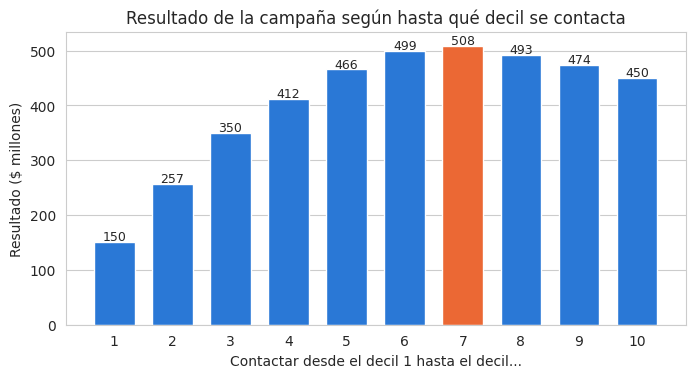

In [92]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(camp.index, camp['resultado'] / 1e6, color=[NARANJA if d == decil_optimo else AZUL for d in camp.index], width=0.7)
for d, v in zip(camp.index, camp['resultado'] / 1e6):
    ax.text(d, v + 3, f'{v:,.0f}', ha='center', fontsize=9)
ax.set_xticks(range(1, 11)); ax.set_xlabel('Contactar desde el decil 1 hasta el decil...'); ax.set_ylabel('Resultado ($ millones)')
ax.set_title('Resultado de la campaña según hasta qué decil se contacta'); ax.grid(axis='x', visible=False)
plt.show()

## 7.2 Grupo de control
Para medir el efecto real de la campaña recomendamos separar al azar un **grupo de control** (por ejemplo el 10% de cada decil contactado) al que **no** se le hace la acción.
Comparando la tasa de compra de contactados vs. control sabemos cuántas ventas generó realmente la campaña y no solo cuántas habrían ocurrido igual.

## 7.3 Lista para Marketing
Score y decil de cada cliente del universo, listos para cargar en la herramienta de campañas.

In [93]:
lista = todos[['client_id', 'score', 'decil']].sort_values('score', ascending=False).reset_index(drop=True)
lista['prioridad'] = np.select([lista.decil <= 2, lista.decil <= decil_optimo], ['Alta', 'Media'], 'No contactar')
lista.to_csv(RUTA + 'lista_clientes_campania.csv', index=False)
print(lista['prioridad'].value_counts())
lista.head(10)

prioridad
Media           11652
No contactar     6991
Alta             4548
Name: count, dtype: int64


,client_id,score,decil,prioridad
0,4949542,0.924535,1,Alta
1,1513750,0.922687,1,Alta
2,4848454,0.921050,1,Alta
3,5475975,0.919973,1,Alta
4,139860,0.919830,1,Alta
5,327280,0.919774,1,Alta
6,21323,0.918390,1,Alta
7,20725,0.914825,1,Alta
8,5589265,0.912678,1,Alta
9,4710578,0.912106,1,Alta


# 6. Conclusiones
*(Números de nuestra corrida. Si se vuelve a correr en Colab con otra versión de LightGBM pueden variar en el tercer decimal.)*

**Universo y target**
- 23.191 clientes sin paquete y sin tarjeta co-branding. El 29,4% compró el producto en marzo o abril 2019.

**Del TP individual al modelo**
- Se usó la ABT del TP individual (685 variables). Se sacaron 462 variables muy correlacionadas (más de 0,80) y el modelo final usa las **15 más importantes**.
- El % de target de tarjeta, región y edad se recalculó solo con train para no filtrar información del test. Los valores cambian como mucho unos 2 puntos, pero así la evaluación es honesta.

**El modelo funciona y es estable**
- AUC de 0,84 en test (clientes que el modelo no vio) contra 0,85 en train: la diferencia es chica, no hay sobreajuste.
- Supera la referencia de clase (AUC 0,818).

**Lo que gana Marketing**
- En el **decil 1 compra el 75%** de los clientes, 2,6 veces más que el promedio (lift 2,6).
- Contactando al **30% de la base con mejor score se captura el 62% de los compradores**; con el 50%, el 86%.
- Los deciles 8, 9 y 10 casi no compran (menos del 5%): contactarlos es gastar sin retorno.

**Perfil del cliente que compra** (variables top)
- **Tiene tarjeta de crédito activa**: es la variable más importante. Con tarjeta compra el 42%, sin tarjeta solo el 6%.
- **Mantiene o aumenta el consumo con tarjeta** respecto de 6 meses atrás (los que lo bajaron mucho compran menos).
- **Usa mucho la cuenta**: con más plata movida en la caja de ahorro la compra sube del 18% al 56%.
- **Cobra el sueldo en el banco**: entre los que cobran los sueldos más altos compra el 75%.
- **Va a la sucursal**: con 5 o más operaciones por caja compra el 57%.
- **Es más grande de edad** y **sacó un producto hace poco** (en promedio hace 8 meses en el decil 1, contra 55 en el decil 5).

**Recomendación de campaña** (supuestos: $10.000 por contacto, $100.000 de ganancia por venta)
- Contactar **hasta el decil 7**: resultado de ~$506 M contra ~$450 M si se contacta a todos, con un 30% menos de contactos y el 98% de los compradores.
- Si el canal es más caro, el punto óptimo baja (menos deciles); la celda 7.1 permite cambiar los supuestos.
- Separar un **grupo de control** para medir el efecto real de la campaña, y **volver a scorear la base cada mes**.

**Limitaciones**
- Tipo de tarjeta y región se completaron con datos de marzo 2019 (no existían en la historia).
- Los montos de costo y ganancia son supuestos de ejemplo de clase: hay que reemplazarlos por los reales del producto.